In [1]:
# ============================================
# 09 - FINAL PREDICTIONS AND EVALUATION
# Cell 1: Imports
# ============================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

print("All libraries imported successfully.")
print("PyTorch version:", torch.__version__)

All libraries imported successfully.
PyTorch version: 2.6.0+cpu


In [2]:
# ============================================
# Cell 2: Paths and Device
# ============================================

DATA_DIR = "data"
MODEL_DIR = "models"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Data directory:", DATA_DIR)
print("Model directory:", MODEL_DIR)

Device: cpu
Data directory: data
Model directory: models


In [3]:
# ============================================
# Cell 3: Load Phase 1 Data
# ============================================

node_features = pd.read_csv(
    os.path.join(DATA_DIR, "node_features.csv")
)

grid_nodes = pd.read_csv(
    os.path.join(DATA_DIR, "chicago_spatial_grid.csv")
)

print("Node features shape:", node_features.shape)
print("Grid nodes shape:", grid_nodes.shape)

print("\nNode feature columns:")
print(node_features.columns.tolist())

Node features shape: (157, 33)
Grid nodes shape: (157, 6)

Node feature columns:
['GRID_ID', 'CRIME_FREQUENCY', 'MEAN_DAILY_CRIME', 'MAX_DAILY_CRIME', 'ACTIVE_DAYS', 'CRIME_FREQUENCY_Z', 'GRID_ROW', 'GRID_COL', 'GRID_CENTER_LAT', 'GRID_CENTER_LON', 'ASSAULT', 'BATTERY', 'BURGLARY', 'CRIMINAL DAMAGE', 'CRIMINAL SEXUAL ASSAULT', 'CRIMINAL TRESPASS', 'DECEPTIVE PRACTICE', 'MOTOR VEHICLE THEFT', 'NARCOTICS', 'OFFENSE INVOLVING CHILDREN', 'OTHER', 'OTHER OFFENSE', 'PUBLIC PEACE VIOLATION', 'ROBBERY', 'SEX OFFENSE', 'THEFT', 'WEAPONS VIOLATION', 'CRIME_TYPE_SUM', 'TYPE_COUNT_DIFFERENCE', 'LAT_NORM', 'LON_NORM', 'TARGET_CRIME_TYPE', 'TARGET']


In [4]:
# ============================================
# Cell 4: Load Phase 1 Model
# ============================================

phase1_model_path = os.path.join(
    MODEL_DIR,
    "phase1_crime_gcn.pth"
)

checkpoint_phase1 = torch.load(
    phase1_model_path,
    map_location=device,
    weights_only=False
)

print("Phase 1 model loaded successfully.")

print("\nModel information:")
print("Input features:", checkpoint_phase1["input_features"])
print("Hidden features:", checkpoint_phase1["hidden_features"])
print("Output classes:", checkpoint_phase1["output_classes"])
print("Dropout:", checkpoint_phase1["dropout"])
print("Best epoch:", checkpoint_phase1["best_epoch"])
print("Best validation Macro F1:",
      checkpoint_phase1["best_validation_macro_f1"])

Phase 1 model loaded successfully.

Model information:
Input features: 23
Hidden features: 128
Output classes: 7
Dropout: 0.5
Best epoch: 23
Best validation Macro F1: 0.5625


In [5]:
# ============================================
# Cell 5: Recreate Phase 1 GCN
# ============================================

class GCN(nn.Module):

    def __init__(
        self,
        input_features,
        hidden_features,
        output_classes,
        dropout=0.5
    ):
        super().__init__()

        self.conv1 = GCNConv(
            input_features,
            hidden_features
        )

        self.conv2 = GCNConv(
            hidden_features,
            output_classes
        )

        self.dropout = dropout

    def forward(self, x, edge_index):

        x = self.conv1(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.conv2(
            x,
            edge_index
        )

        return x

In [6]:
# ============================================
# Cell 6: Load Phase 1 Graph
# ============================================

graph_path = os.path.join(
    MODEL_DIR,
    "phase1_graph.pt"
)

graph_checkpoint = torch.load(
    graph_path,
    map_location=device,
    weights_only=False
)

edge_index_phase1 = graph_checkpoint["edge_index"]
edge_weight_phase1 = graph_checkpoint["edge_weight"]

print("Phase 1 graph loaded successfully.")
print("Edge index shape:", edge_index_phase1.shape)

if edge_weight_phase1 is not None:
    print("Edge weight shape:", edge_weight_phase1.shape)
else:
    print("No edge weights found.")

Phase 1 graph loaded successfully.
Edge index shape: torch.Size([2, 544])
No edge weights found.


In [7]:
# ============================================
# Cell 7: Prepare Phase 1 Features
# ============================================

feature_columns = checkpoint_phase1["feature_columns"]
class_names = checkpoint_phase1["class_names"]

print("Number of features:", len(feature_columns))
print("\nFeatures:")
for i, feature in enumerate(feature_columns, start=1):
    print(f"{i:2d}. {feature}")

print("\nClasses:")
for i, class_name in enumerate(class_names):
    print(f"{i}: {class_name}")

Number of features: 23

Features:
 1. LAT_NORM
 2. LON_NORM
 3. CRIME_FREQUENCY_Z
 4. MEAN_DAILY_CRIME
 5. MAX_DAILY_CRIME
 6. ACTIVE_DAYS
 7. ASSAULT
 8. BATTERY
 9. BURGLARY
10. CRIMINAL DAMAGE
11. CRIMINAL SEXUAL ASSAULT
12. CRIMINAL TRESPASS
13. DECEPTIVE PRACTICE
14. MOTOR VEHICLE THEFT
15. NARCOTICS
16. OFFENSE INVOLVING CHILDREN
17. OTHER
18. OTHER OFFENSE
19. PUBLIC PEACE VIOLATION
20. ROBBERY
21. SEX OFFENSE
22. THEFT
23. WEAPONS VIOLATION

Classes:
0: ASSAULT
1: BATTERY
2: CRIMINAL DAMAGE
3: DECEPTIVE PRACTICE
4: MOTOR VEHICLE THEFT
5: SEX OFFENSE
6: THEFT


In [8]:
# ============================================
# Cell 8: Create Feature Tensor
# ============================================

X_phase1 = node_features[feature_columns].copy()

print("Feature matrix shape:", X_phase1.shape)
print("Missing values:", X_phase1.isna().sum().sum())
print("Infinite values:", np.isinf(X_phase1.values).sum())

Feature matrix shape: (157, 23)
Missing values: 0
Infinite values: 0


In [9]:
# ============================================
# Cell 9: Create Graph Data
# ============================================

X_tensor_phase1 = torch.tensor(
    X_phase1.values,
    dtype=torch.float32
).to(device)

graph_data_phase1 = {
    "x": X_tensor_phase1,
    "edge_index": edge_index_phase1.to(device)
}

print("Graph ready.")
print("Nodes:", X_tensor_phase1.shape[0])
print("Features per node:", X_tensor_phase1.shape[1])
print("Edges:", edge_index_phase1.shape[1])

Graph ready.
Nodes: 157
Features per node: 23
Edges: 544


In [10]:
# ============================================
# Cell 10: Restore Trained Phase 1 Model
# ============================================

model_phase1 = GCN(
    input_features=checkpoint_phase1["input_features"],
    hidden_features=checkpoint_phase1["hidden_features"],
    output_classes=checkpoint_phase1["output_classes"],
    dropout=checkpoint_phase1["dropout"]
)

model_phase1.load_state_dict(
    checkpoint_phase1["model_state_dict"]
)

model_phase1 = model_phase1.to(device)
model_phase1.eval()

print("Trained Phase 1 GCN restored successfully.")
print(model_phase1)

Trained Phase 1 GCN restored successfully.
GCN(
  (conv1): GCNConv(23, 128)
  (conv2): GCNConv(128, 7)
)


In [11]:
# ============================================
# Cell 11: Generate Phase 1 Predictions
# ============================================

with torch.no_grad():

    logits = model_phase1(
        graph_data_phase1["x"],
        graph_data_phase1["edge_index"]
    )

    probabilities = F.softmax(
        logits,
        dim=1
    )

    predicted_classes = torch.argmax(
        probabilities,
        dim=1
    )

predicted_classes = predicted_classes.cpu().numpy()
probabilities = probabilities.cpu().numpy()

print("Predictions generated successfully.")
print("Number of predictions:", len(predicted_classes))
print("Probability matrix shape:", probabilities.shape)

Predictions generated successfully.
Number of predictions: 157
Probability matrix shape: (157, 7)


In [12]:
# ============================================
# Cell 12: Phase 1 Prediction Table
# ============================================

phase1_predictions = pd.DataFrame({
    "GRID_ID": node_features["GRID_ID"].values,
    "GRID_CENTER_LAT": node_features["GRID_CENTER_LAT"].values,
    "GRID_CENTER_LON": node_features["GRID_CENTER_LON"].values,
    "ACTUAL_CRIME_TYPE": node_features["TARGET_CRIME_TYPE"].values,
    "PREDICTED_CRIME_TYPE": [
        class_names[i]
        for i in predicted_classes
    ],
    "PREDICTION_CONFIDENCE": probabilities.max(axis=1)
})

phase1_predictions["CORRECT"] = (
    phase1_predictions["ACTUAL_CRIME_TYPE"] ==
    phase1_predictions["PREDICTED_CRIME_TYPE"]
)

print("Prediction table created.")
print("\nShape:", phase1_predictions.shape)

phase1_predictions.head(10)

Prediction table created.

Shape: (157, 7)


,GRID_ID,GRID_CENTER_LAT,GRID_CENTER_LON,ACTUAL_CRIME_TYPE,PREDICTED_CRIME_TYPE,PREDICTION_CONFIDENCE,CORRECT
0,0_10,41.654305,-87.617586,BATTERY,BATTERY,0.860396,True
1,0_11,41.654444,-87.591166,BATTERY,CRIMINAL DAMAGE,0.987257,False
2,0_12,41.654577,-87.564745,BATTERY,CRIMINAL DAMAGE,0.928592,False
3,0_13,41.654704,-87.538324,CRIMINAL DAMAGE,CRIMINAL DAMAGE,0.920250,True
4,0_9,41.654160,-87.644006,THEFT,BATTERY,0.462161,False
5,10_10,41.852449,-87.619488,THEFT,THEFT,1.000000,True
6,10_6,41.851828,-87.725493,BATTERY,BATTERY,1.000000,True
7,10_7,41.851992,-87.698993,BATTERY,BATTERY,1.000000,True
8,10_8,41.852151,-87.672491,THEFT,THEFT,0.999938,True
9,10_9,41.852303,-87.645990,THEFT,THEFT,1.000000,True


In [13]:
# ============================================
# Cell 13: Prediction Distribution
# ============================================

print("Actual class distribution:")
print(
    phase1_predictions["ACTUAL_CRIME_TYPE"]
    .value_counts()
)

print("\nPredicted class distribution:")
print(
    phase1_predictions["PREDICTED_CRIME_TYPE"]
    .value_counts()
)

Actual class distribution:
ACTUAL_CRIME_TYPE
BATTERY                76
THEFT                  71
DECEPTIVE PRACTICE      3
CRIMINAL DAMAGE         2
MOTOR VEHICLE THEFT     2
ASSAULT                 2
SEX OFFENSE             1
Name: count, dtype: int64

Predicted class distribution:
PREDICTED_CRIME_TYPE
BATTERY               67
THEFT                 45
DECEPTIVE PRACTICE    36
CRIMINAL DAMAGE        9
Name: count, dtype: int64


In [14]:
# ============================================
# Cell 14: Final Phase 1 Metrics
# ============================================

y_actual = phase1_predictions["ACTUAL_CRIME_TYPE"]
y_predicted = phase1_predictions["PREDICTED_CRIME_TYPE"]

phase1_accuracy = accuracy_score(
    y_actual,
    y_predicted
)

phase1_precision = precision_score(
    y_actual,
    y_predicted,
    average="macro",
    zero_division=0
)

phase1_recall = recall_score(
    y_actual,
    y_predicted,
    average="macro",
    zero_division=0
)

phase1_macro_f1 = f1_score(
    y_actual,
    y_predicted,
    average="macro",
    zero_division=0
)

phase1_weighted_f1 = f1_score(
    y_actual,
    y_predicted,
    average="weighted",
    zero_division=0
)

print("========== PHASE 1 FINAL RESULTS ==========")
print(f"Accuracy       : {phase1_accuracy:.4f}")
print(f"Macro Precision: {phase1_precision:.4f}")
print(f"Macro Recall   : {phase1_recall:.4f}")
print(f"Macro F1       : {phase1_macro_f1:.4f}")
print(f"Weighted F1    : {phase1_weighted_f1:.4f}")

========== PHASE 1 FINAL RESULTS ==========
Accuracy       : 0.5987
Macro Precision: 0.2751
Macro Recall   : 0.4583
Macro F1       : 0.2704
Weighted F1    : 0.6512


In [15]:
# ============================================
# Cell 15: Classification Report
# ============================================

print(
    classification_report(
        y_actual,
        y_predicted,
        labels=class_names,
        zero_division=0
    )
)

                     precision    recall  f1-score   support

            ASSAULT       0.00      0.00      0.00         2
            BATTERY       0.73      0.64      0.69        76
    CRIMINAL DAMAGE       0.22      1.00      0.36         2
 DECEPTIVE PRACTICE       0.08      1.00      0.15         3
MOTOR VEHICLE THEFT       0.00      0.00      0.00         2
        SEX OFFENSE       0.00      0.00      0.00         1
              THEFT       0.89      0.56      0.69        71

           accuracy                           0.60       157
          macro avg       0.28      0.46      0.27       157
       weighted avg       0.76      0.60      0.65       157



In [16]:
# ============================================
# Cell 16: Phase 1 Confusion Matrix
# ============================================

cm_phase1 = confusion_matrix(
    y_actual,
    y_predicted,
    labels=class_names
)

print("Confusion Matrix:")
print(cm_phase1)

Confusion Matrix:
[[ 0  0  0  2  0  0  0]
 [ 0 49  5 17  0  0  5]
 [ 0  0  2  0  0  0  0]
 [ 0  0  0  3  0  0  0]
 [ 0  0  0  2  0  0  0]
 [ 0  0  1  0  0  0  0]
 [ 0 18  1 12  0  0 40]]


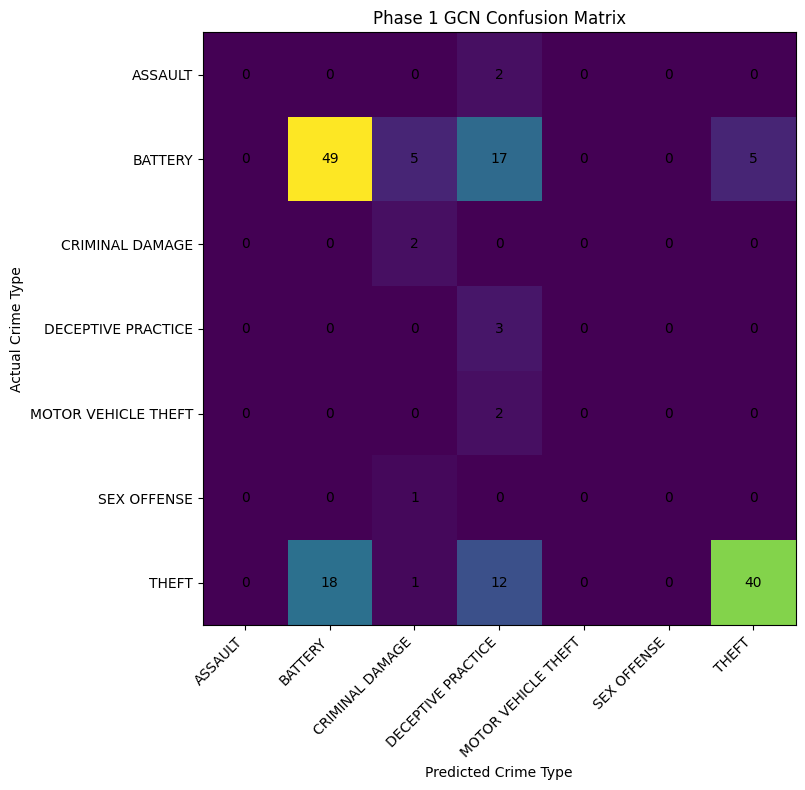

In [17]:
# ============================================
# Cell 17: Plot Phase 1 Confusion Matrix
# ============================================

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(cm_phase1)

ax.set_xticks(np.arange(len(class_names)))
ax.set_yticks(np.arange(len(class_names)))

ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticklabels(class_names)

ax.set_xlabel("Predicted Crime Type")
ax.set_ylabel("Actual Crime Type")
ax.set_title("Phase 1 GCN Confusion Matrix")

for i in range(len(class_names)):
    for j in range(len(class_names)):
        ax.text(
            j,
            i,
            cm_phase1[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [18]:
# ============================================
# Cell 18: Save Phase 1 Predictions
# ============================================

os.makedirs(DATA_DIR, exist_ok=True)

phase1_prediction_path = os.path.join(
    DATA_DIR,
    "phase1_predictions.csv"
)

phase1_predictions.to_csv(
    phase1_prediction_path,
    index=False
)

print("Saved:", phase1_prediction_path)
print("Rows saved:", len(phase1_predictions))

Saved: data\phase1_predictions.csv
Rows saved: 157


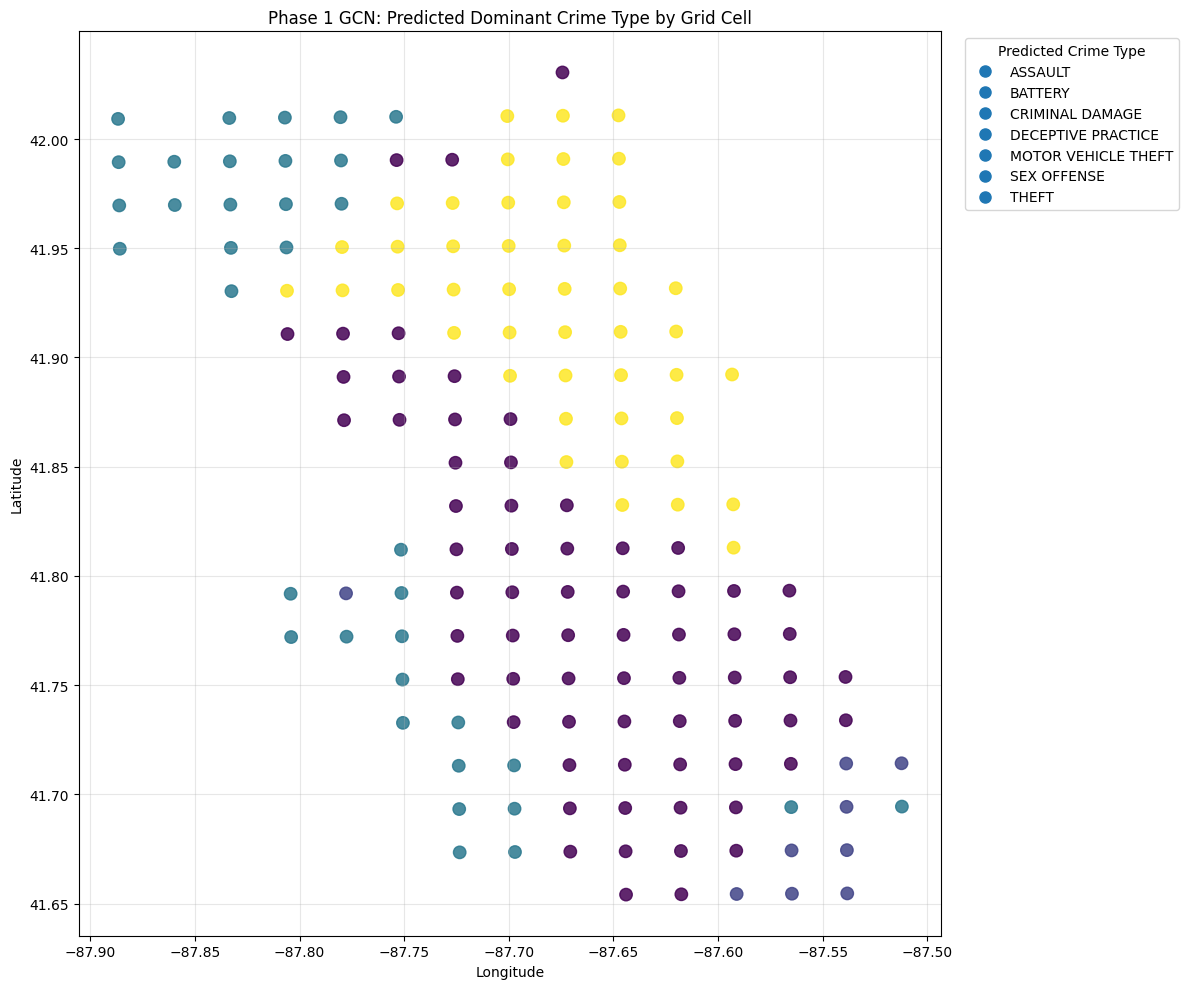

In [19]:
# ============================================
# Cell 19: Phase 1 Spatial Prediction Map
# ============================================

fig, ax = plt.subplots(figsize=(12, 10))

scatter = ax.scatter(
    phase1_predictions["GRID_CENTER_LON"],
    phase1_predictions["GRID_CENTER_LAT"],
    c=pd.Categorical(
        phase1_predictions["PREDICTED_CRIME_TYPE"],
        categories=class_names
    ).codes,
    s=80,
    alpha=0.85
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(
    "Phase 1 GCN: Predicted Dominant Crime Type by Grid Cell"
)

# Create legend
handles = []

for i, class_name in enumerate(class_names):
    handles.append(
        plt.Line2D(
            [0],
            [0],
            marker="o",
            linestyle="",
            markersize=8,
            label=class_name
        )
    )

ax.legend(
    handles=handles,
    title="Predicted Crime Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

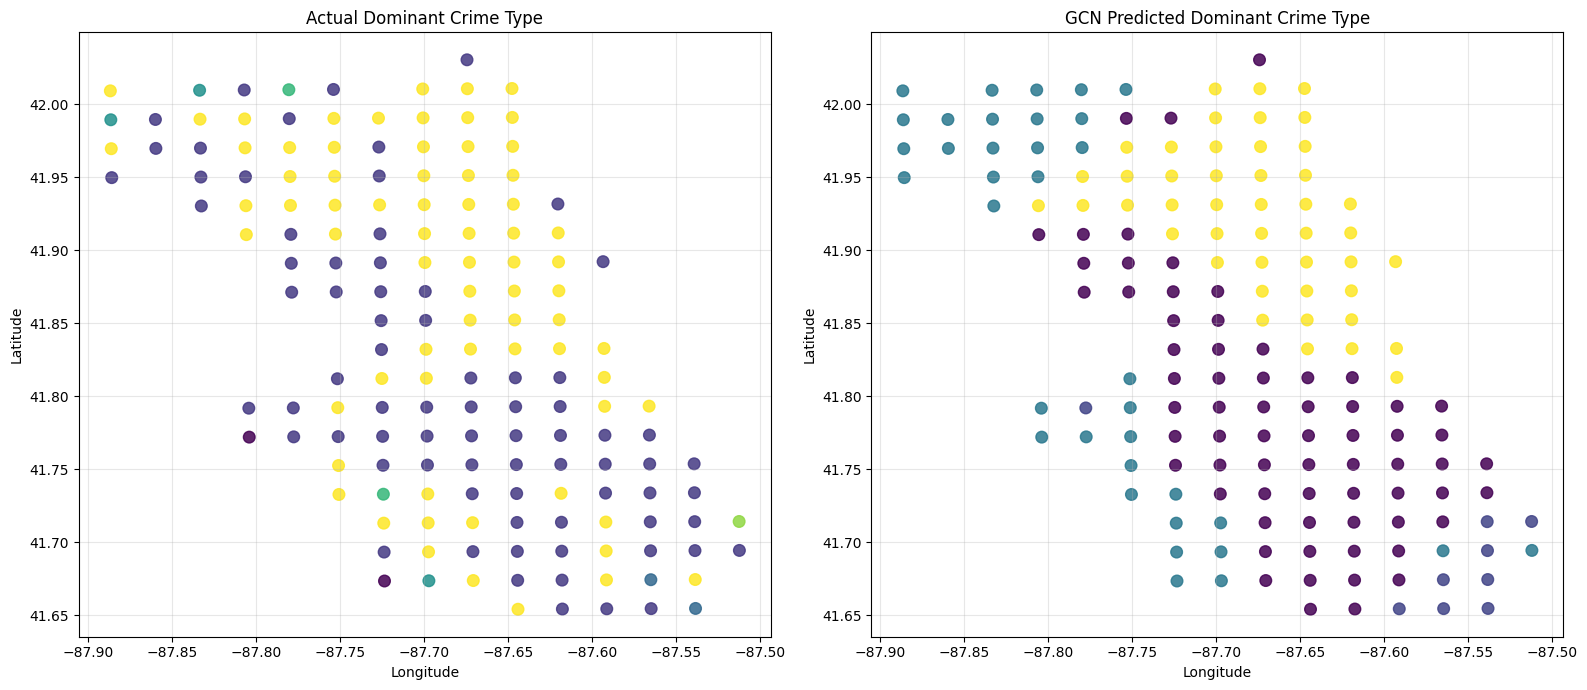

In [20]:
# ============================================
# Cell 20: Actual vs Predicted Comparison
# ============================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7)
)

# Actual
actual_codes = pd.Categorical(
    phase1_predictions["ACTUAL_CRIME_TYPE"],
    categories=class_names
).codes

axes[0].scatter(
    phase1_predictions["GRID_CENTER_LON"],
    phase1_predictions["GRID_CENTER_LAT"],
    c=actual_codes,
    s=70,
    alpha=0.85
)

axes[0].set_title("Actual Dominant Crime Type")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].grid(True, alpha=0.3)

# Predicted
predicted_codes = pd.Categorical(
    phase1_predictions["PREDICTED_CRIME_TYPE"],
    categories=class_names
).codes

axes[1].scatter(
    phase1_predictions["GRID_CENTER_LON"],
    phase1_predictions["GRID_CENTER_LAT"],
    c=predicted_codes,
    s=70,
    alpha=0.85
)

axes[1].set_title("GCN Predicted Dominant Crime Type")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

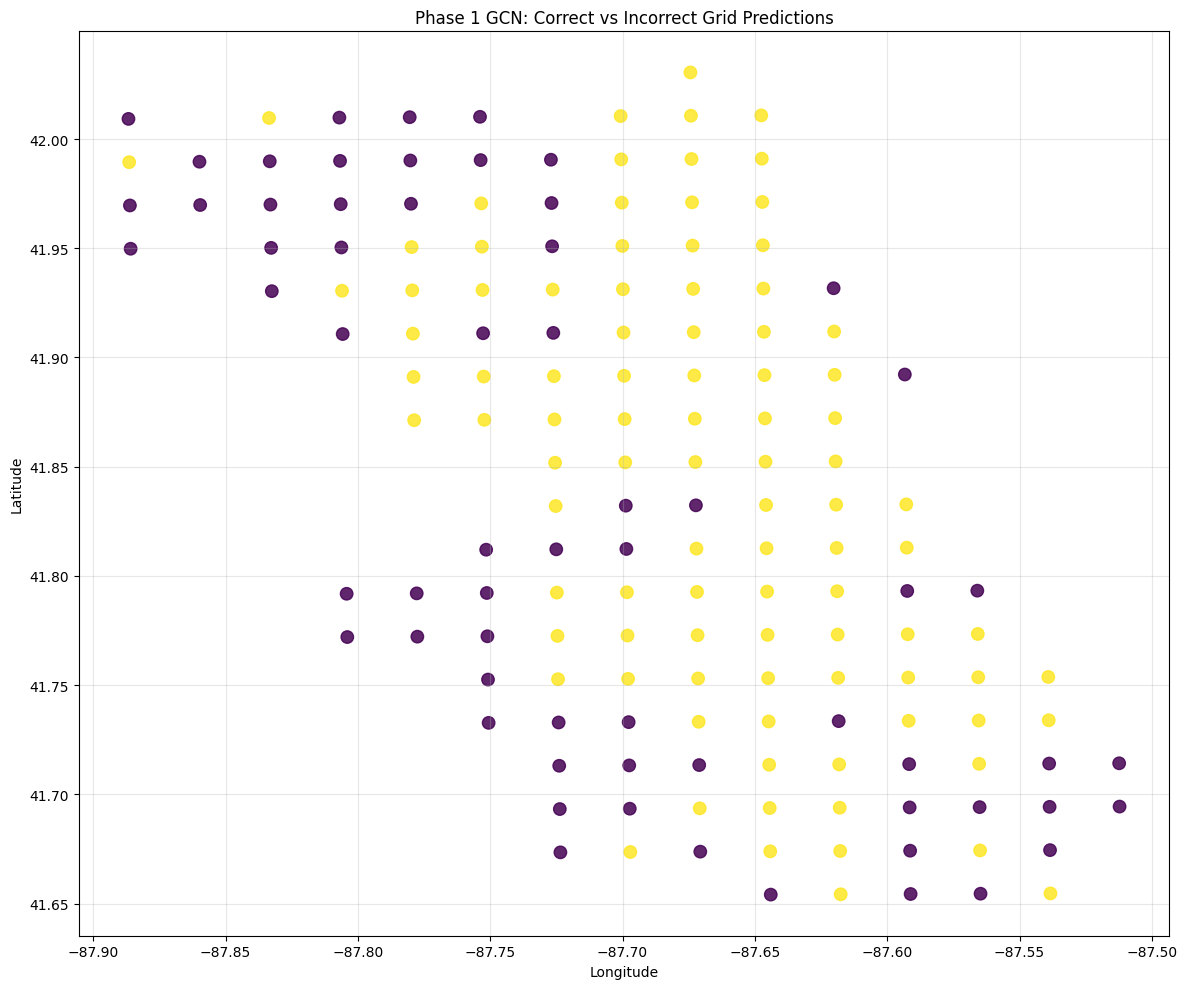

In [21]:
# ============================================
# Cell 21: Correct vs Incorrect Predictions
# ============================================

fig, ax = plt.subplots(figsize=(12, 10))

correct_codes = phase1_predictions["CORRECT"].map({
    True: 1,
    False: 0
})

ax.scatter(
    phase1_predictions["GRID_CENTER_LON"],
    phase1_predictions["GRID_CENTER_LAT"],
    c=correct_codes,
    s=80,
    alpha=0.85
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(
    "Phase 1 GCN: Correct vs Incorrect Grid Predictions"
)

ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

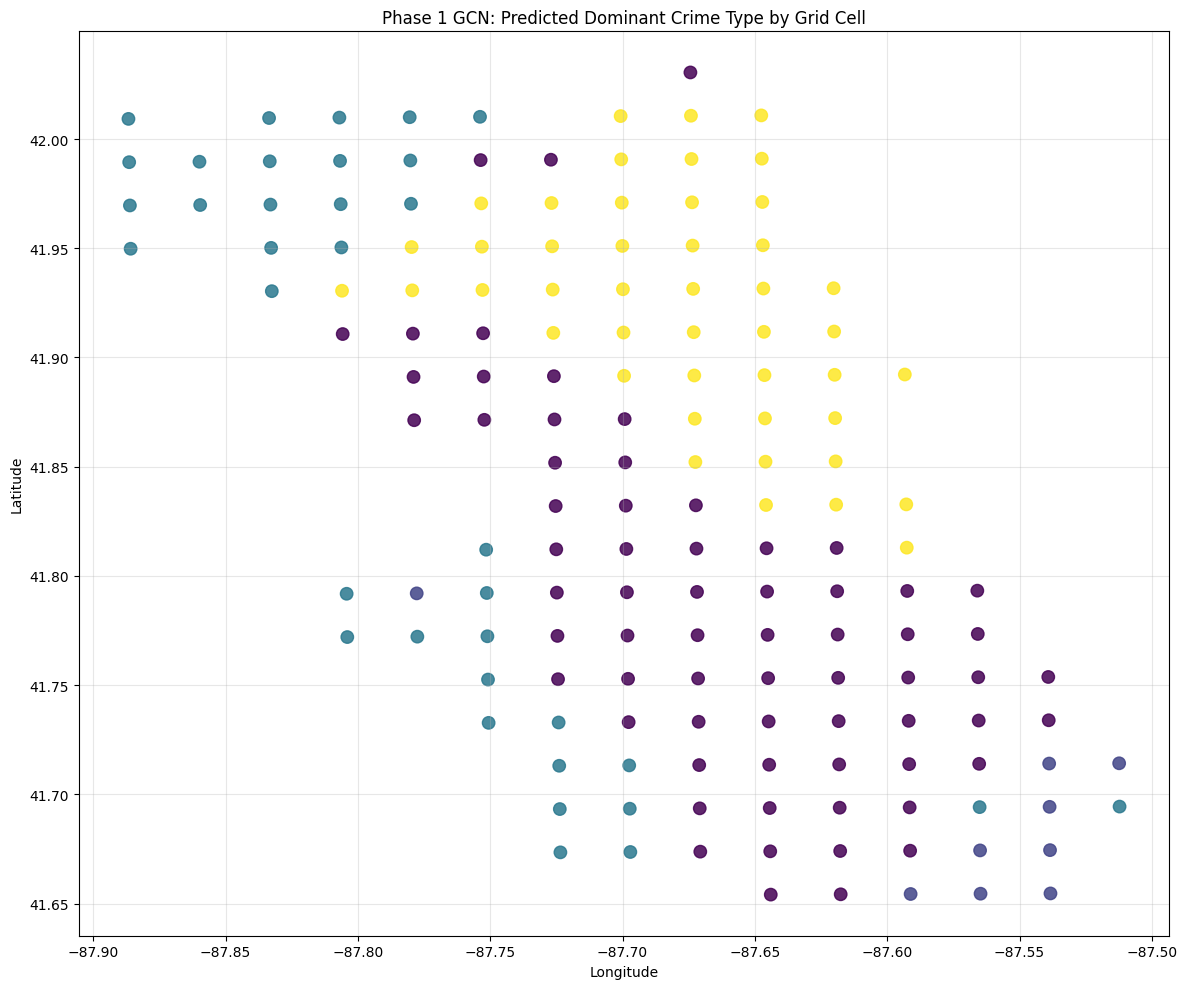

Phase 1 spatial map saved.


In [22]:
# ============================================
# Cell 22: Save Phase 1 Figures
# ============================================

FIGURE_DIR = "figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

# Predicted map
fig, ax = plt.subplots(figsize=(12, 10))

ax.scatter(
    phase1_predictions["GRID_CENTER_LON"],
    phase1_predictions["GRID_CENTER_LAT"],
    c=predicted_codes,
    s=80,
    alpha=0.85
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(
    "Phase 1 GCN: Predicted Dominant Crime Type by Grid Cell"
)
ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "phase1_predicted_crime_map.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Phase 1 spatial map saved.")

In [23]:
# ============================================================
# CELL 23 — PHASE 2: LOAD MODEL AND SCALER
# ============================================================

import joblib
import json
import torch
import pandas as pd
import numpy as np

# Load Phase 2 model
phase2_checkpoint = torch.load(
    "models/phase2_victimisation_gcn.pth",
    map_location=device,
    weights_only=False
)

# Load scaler
scaler_phase2 = joblib.load(
    "models/phase2_scaler.pkl"
)

# Load label information
with open("models/phase2_label_info.json", "r") as f:
    phase2_label_info = json.load(f)

print("Phase 2 model loaded successfully.")
print("Label information:", phase2_label_info)

Phase 2 model loaded successfully.
Label information: {'0': 'Low Victimisation Risk', '1': 'High Victimisation Risk'}


In [24]:
# ============================================================
# CELL 24 — RECREATE PHASE 2 GCN
# ============================================================

class VictimisationGCN(torch.nn.Module):
    def __init__(
        self,
        input_features,
        hidden_features,
        output_classes,
        dropout=0.5
    ):
        super().__init__()

        self.conv1 = GCNConv(
            input_features,
            hidden_features
        )

        self.conv2 = GCNConv(
            hidden_features,
            output_classes
        )

        self.dropout = dropout

    def forward(self, x, edge_index, edge_weight=None):

        x = self.conv1(
            x,
            edge_index,
            edge_weight=edge_weight
        )

        x = torch.relu(x)

        x = torch.nn.functional.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.conv2(
            x,
            edge_index,
            edge_weight=edge_weight
        )

        return x


model_phase2 = VictimisationGCN(
    input_features=phase2_checkpoint["input_features"],
    hidden_features=phase2_checkpoint["hidden_features"],
    output_classes=phase2_checkpoint["output_classes"],
    dropout=phase2_checkpoint["dropout"]
)

model_phase2.load_state_dict(
    phase2_checkpoint["model_state_dict"]
)

model_phase2 = model_phase2.to(device)
model_phase2.eval()

print(model_phase2)

VictimisationGCN(
  (conv1): GCNConv(10, 128)
  (conv2): GCNConv(128, 2)
)


In [25]:
# ============================================================
# FIX HIST_DOMESTIC AND HIST_ARREST
# ============================================================

import pandas as pd
import numpy as np
from pyproj import Transformer

# Load the Phase 2 dataset
phase2_dataset = pd.read_csv(
    "data/phase2_victimisation_dataset.csv"
)

# Load the original cleaned crime data
crime_df = pd.read_csv(
    "data/chicago_crime_cleaned.csv"
)

crime_df["DATE_OF_OCCURRENCE"] = pd.to_datetime(
    crime_df["DATE_OF_OCCURRENCE"],
    errors="coerce"
)

# ------------------------------------------------------------
# Convert ARREST and DOMESTIC from Y/N to 0/1
# ------------------------------------------------------------

crime_df["ARREST_FLAG"] = (
    crime_df["ARREST"]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("Y")
    .astype(int)
)

crime_df["DOMESTIC_FLAG"] = (
    crime_df["DOMESTIC"]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("Y")
    .astype(int)
)

# ------------------------------------------------------------
# Recreate GRID_ID using the EXACT SAME grid definition
# ------------------------------------------------------------

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:26916",
    always_xy=True
)

crime_df["X_M"], crime_df["Y_M"] = transformer.transform(
    crime_df["LONGITUDE"].values,
    crime_df["LATITUDE"].values
)

GRID_SIZE = 2200

MIN_X = 425476.99038882746
MIN_Y = 4610479.474780203

crime_df["GRID_ROW"] = np.floor(
    (crime_df["Y_M"] - MIN_Y) / GRID_SIZE
).astype(int)

crime_df["GRID_COL"] = np.floor(
    (crime_df["X_M"] - MIN_X) / GRID_SIZE
).astype(int)

crime_df["GRID_ID"] = (
    crime_df["GRID_ROW"].astype(str)
    + "_"
    + crime_df["GRID_COL"].astype(str)
)

# ------------------------------------------------------------
# Historical period
# ------------------------------------------------------------

cutoff_date = pd.Timestamp(
    "2026-06-12 00:00:00"
)

history_df = crime_df[
    crime_df["DATE_OF_OCCURRENCE"] < cutoff_date
].copy()

# ------------------------------------------------------------
# Calculate correct historical values
# ------------------------------------------------------------

fixed_history = (
    history_df
    .groupby("GRID_ID")
    .agg(
        HIST_DOMESTIC=("DOMESTIC_FLAG", "sum"),
        HIST_ARREST=("ARREST_FLAG", "sum")
    )
    .reset_index()
)

# ------------------------------------------------------------
# Remove broken columns
# ------------------------------------------------------------

phase2_dataset = phase2_dataset.drop(
    columns=[
        "HIST_DOMESTIC",
        "HIST_ARREST"
    ]
)

# ------------------------------------------------------------
# Merge correct values
# ------------------------------------------------------------

phase2_dataset = phase2_dataset.merge(
    fixed_history,
    on="GRID_ID",
    how="left"
)

# Cells with no historical crimes = 0
phase2_dataset["HIST_DOMESTIC"] = (
    phase2_dataset["HIST_DOMESTIC"]
    .fillna(0)
)

phase2_dataset["HIST_ARREST"] = (
    phase2_dataset["HIST_ARREST"]
    .fillna(0)
)

# Convert to numeric
phase2_dataset["HIST_DOMESTIC"] = (
    phase2_dataset["HIST_DOMESTIC"]
    .astype(float)
)

phase2_dataset["HIST_ARREST"] = (
    phase2_dataset["HIST_ARREST"]
    .astype(float)
)

# ------------------------------------------------------------
# Save corrected dataset
# ------------------------------------------------------------

phase2_dataset.to_csv(
    "data/phase2_dataset.csv",
    index=False
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("Phase 2 dataset corrected successfully.")
print("Shape:", phase2_dataset.shape)

print("\nMissing values:")
print(
    phase2_dataset[
        ["HIST_DOMESTIC", "HIST_ARREST"]
    ].isna().sum()
)

print("\nData types:")
print(
    phase2_dataset[
        ["HIST_DOMESTIC", "HIST_ARREST"]
    ].dtypes
)

print("\nSample:")
print(
    phase2_dataset[
        [
            "GRID_ID",
            "HIST_TOTAL_CRIME",
            "HIST_VICTIMISATION",
            "HIST_DOMESTIC",
            "HIST_ARREST"
        ]
    ].head(10)
)

Phase 2 dataset corrected successfully.
Shape: (157, 48)

Missing values:
HIST_DOMESTIC    0
HIST_ARREST      0
dtype: int64

Data types:
HIST_DOMESTIC    float64
HIST_ARREST      float64
dtype: object

Sample:
  GRID_ID  HIST_TOTAL_CRIME  HIST_VICTIMISATION  HIST_DOMESTIC  HIST_ARREST
0     0_9             169.0                46.0           50.0         20.0
1    0_10             458.0               213.0          177.0         60.0
2    0_11             431.0               209.0          152.0         72.0
3    0_12             102.0                34.0           23.0          7.0
4    0_13             341.0               117.0           80.0         29.0
5     1_6               0.0                 0.0            0.0          0.0
6     1_7              18.0                 4.0            6.0          0.0
7     1_8             357.0                92.0           75.0         63.0
8     1_9            1020.0               366.0          286.0        146.0
9    1_10             909.0  

In [26]:
# ============================================================
# CELL 25 — PREPARE PHASE 2 FEATURES
# ============================================================

phase2_checkpoint = torch.load(
    "models/phase2_victimisation_gcn.pth",
    map_location=device,
    weights_only=False
)

scaler_phase2 = joblib.load(
    "models/phase2_scaler.pkl"
)

phase2_feature_columns = phase2_checkpoint["feature_columns"]

X_phase2 = phase2_dataset[
    phase2_feature_columns
].copy()

# Ensure numeric
for column in phase2_feature_columns:
    X_phase2[column] = pd.to_numeric(
        X_phase2[column],
        errors="coerce"
    )

print("Missing values:")
print(X_phase2.isna().sum())

if X_phase2.isna().any().any():
    raise ValueError(
        "Missing values still exist."
    )

X_phase2_scaled = scaler_phase2.transform(
    X_phase2
)

X_phase2_tensor = torch.tensor(
    X_phase2_scaled,
    dtype=torch.float32
).to(device)

print("\nScaled feature shape:")
print(X_phase2_tensor.shape)

print("\nPhase 2 features are ready.")

Missing values:
GRID_CENTER_LAT               0
GRID_CENTER_LON               0
HIST_TOTAL_CRIME              0
HIST_VICTIMISATION            0
HIST_DOMESTIC                 0
HIST_ARREST                   0
HIST_UNIQUE_CRIMES            0
HIST_UNIQUE_LOCATIONS         0
HIST_VICTIMISATION_RATE       0
HIST_VICTIMISATION_PER_DAY    0
dtype: int64

Scaled feature shape:
torch.Size([157, 10])

Phase 2 features are ready.


In [27]:
# ============================================================
# CELL 27 — Prepare Phase 2 Graph Data
# ============================================================

import numpy as np
import pandas as pd
import torch
from torch_geometric.data import Data
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. Load Phase 2 dataset
# ------------------------------------------------------------

phase2_dataset = pd.read_csv("data/phase2_dataset.csv")

print("Phase 2 dataset:", phase2_dataset.shape)

# ------------------------------------------------------------
# 2. Feature columns
# ------------------------------------------------------------

phase2_feature_columns = [
    "GRID_CENTER_LAT",
    "GRID_CENTER_LON",
    "HIST_TOTAL_CRIME",
    "HIST_VICTIMISATION",
    "HIST_DOMESTIC",
    "HIST_ARREST",
    "HIST_UNIQUE_CRIMES",
    "HIST_UNIQUE_LOCATIONS",
    "HIST_VICTIMISATION_RATE",
    "HIST_VICTIMISATION_PER_DAY"
]

# ------------------------------------------------------------
# 3. Align with grid_nodes order
# ------------------------------------------------------------

phase2_dataset = (
    grid_nodes[["GRID_ID"]]
    .merge(
        phase2_dataset,
        on="GRID_ID",
        how="left"
    )
)

assert len(phase2_dataset) == len(grid_nodes)
assert phase2_dataset["GRID_ID"].equals(grid_nodes["GRID_ID"])

print("Grid order aligned successfully.")

# ------------------------------------------------------------
# 4. Prepare X and y
# ------------------------------------------------------------

X_all_phase2 = phase2_dataset[
    phase2_feature_columns
].astype(float).values

y_phase2 = phase2_dataset[
    "HIGH_VICTIMISATION_RISK"
].astype(int).values

print("Feature shape:", X_all_phase2.shape)
print("Missing values:", np.isnan(X_all_phase2).sum())

# ------------------------------------------------------------
# 5. Recreate exact train/validation/test split
# ------------------------------------------------------------

indices = np.arange(len(y_phase2))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    stratify=y_phase2,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=y_phase2[temp_idx],
    random_state=42
)

print("\nSplit sizes:")
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

# ------------------------------------------------------------
# 6. Scale using TRAINING data only
# ------------------------------------------------------------

scaler_phase2 = StandardScaler()

X_scaled_phase2 = np.zeros_like(
    X_all_phase2,
    dtype=np.float64
)

X_scaled_phase2[train_idx] = scaler_phase2.fit_transform(
    X_all_phase2[train_idx]
)

X_scaled_phase2[val_idx] = scaler_phase2.transform(
    X_all_phase2[val_idx]
)

X_scaled_phase2[test_idx] = scaler_phase2.transform(
    X_all_phase2[test_idx]
)

X_all_scaled_tensor_phase2 = torch.tensor(
    X_scaled_phase2,
    dtype=torch.float32
)

print("\nScaled feature tensor:")
print(X_all_scaled_tensor_phase2.shape)

# ------------------------------------------------------------
# 7. Recreate Phase 2 graph
# ------------------------------------------------------------

coords = grid_nodes[
    ["GRID_CENTER_LAT", "GRID_CENTER_LON"]
].values

lat = np.radians(coords[:, 0])
lon = np.radians(coords[:, 1])

lat1 = lat[:, None]
lat2 = lat[None, :]
lon1 = lon[:, None]
lon2 = lon[None, :]

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1)
    * np.cos(lat2)
    * np.sin(dlon / 2) ** 2
)

distance_km = (
    2
    * 6371.0
    * np.arcsin(np.sqrt(a))
)

# 3 km proximity rule
edge_mask = (
    (distance_km <= 3.0)
    & (distance_km > 0)
)

src, dst = np.where(edge_mask)

edge_index_phase2 = torch.tensor(
    np.vstack([src, dst]),
    dtype=torch.long
)

# Inverse-distance edge weights
edge_weight_phase2 = torch.tensor(
    1.0 / (distance_km[src, dst] + 1e-6),
    dtype=torch.float32
)

print("\nPhase 2 graph:")
print("Nodes:", len(grid_nodes))
print("Edges:", edge_index_phase2.shape[1])
print("Edge weights:", len(edge_weight_phase2))

# ------------------------------------------------------------
# 8. Create PyTorch Geometric graph
# ------------------------------------------------------------

graph_data_phase2 = Data(
    x=X_all_scaled_tensor_phase2,
    edge_index=edge_index_phase2,
    edge_weight=edge_weight_phase2,
    y=torch.tensor(
        y_phase2,
        dtype=torch.long
    )
)

print("\nPhase 2 graph data:")
print(graph_data_phase2)

print("\nNodes:", graph_data_phase2.num_nodes)
print("Edges:", graph_data_phase2.num_edges)
print("Features per node:", graph_data_phase2.num_node_features)

Phase 2 dataset: (157, 48)
Grid order aligned successfully.
Feature shape: (157, 10)
Missing values: 0

Split sizes:
Train: 109
Validation: 24
Test: 24

Scaled feature tensor:
torch.Size([157, 10])

Phase 2 graph:
Nodes: 157
Edges: 544
Edge weights: 544

Phase 2 graph data:
Data(x=[157, 10], edge_index=[2, 544], y=[157], edge_weight=[544])

Nodes: 157
Edges: 544
Features per node: 10


In [28]:
# ============================================================
# CELL 28 — Phase 2 GCN Predictions
# ============================================================

model_phase2.eval()

with torch.no_grad():
    logits_phase2 = model_phase2(
        graph_data_phase2.x,
        graph_data_phase2.edge_index,
        graph_data_phase2.edge_weight
    )

    probabilities_phase2 = torch.softmax(
        logits_phase2,
        dim=1
    )

    predictions_phase2 = torch.argmax(
        probabilities_phase2,
        dim=1
    )

print("Prediction complete.")

print("\nLogits shape:")
print(logits_phase2.shape)

print("\nProbability shape:")
print(probabilities_phase2.shape)

print("\nPrediction shape:")
print(predictions_phase2.shape)

print("\nFirst 10 predictions:")
print(predictions_phase2[:10].cpu().numpy())

print("\nFirst 10 probabilities:")
print(probabilities_phase2[:10].cpu().numpy())

Prediction complete.

Logits shape:
torch.Size([157, 2])

Probability shape:
torch.Size([157, 2])

Prediction shape:
torch.Size([157])

First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]

First 10 probabilities:
[[9.9978048e-01 2.1955067e-04]
 [9.9987948e-01 1.2044870e-04]
 [9.9996340e-01 3.6648940e-05]
 [9.9998820e-01 1.1830845e-05]
 [9.9997342e-01 2.6536913e-05]
 [9.9999762e-01 2.4392450e-06]
 [9.9999619e-01 3.8007202e-06]
 [9.9990404e-01 9.5976400e-05]
 [9.9960381e-01 3.9615540e-04]
 [9.9936312e-01 6.3689559e-04]]


In [29]:
# ============================================================
# CELL 29 — Phase 2 Prediction DataFrame
# ============================================================

prediction_df_phase2 = grid_nodes[
    [
        "GRID_ID",
        "GRID_CENTER_LAT",
        "GRID_CENTER_LON",
        "CRIME_COUNT"
    ]
].copy()

# Actual target
prediction_df_phase2["ACTUAL_RISK"] = y_phase2

# Model prediction
prediction_df_phase2["PREDICTED_RISK"] = (
    predictions_phase2.cpu().numpy()
)

# Class probabilities
prediction_df_phase2["LOW_RISK_PROB"] = (
    probabilities_phase2[:, 0]
    .cpu()
    .numpy()
)

prediction_df_phase2["HIGH_RISK_PROB"] = (
    probabilities_phase2[:, 1]
    .cpu()
    .numpy()
)

# Confidence = probability of predicted class
prediction_df_phase2["CONFIDENCE"] = (
    probabilities_phase2.max(dim=1)
    .values
    .cpu()
    .numpy()
)

# Human-readable labels
prediction_df_phase2["ACTUAL_RISK_LABEL"] = (
    prediction_df_phase2["ACTUAL_RISK"]
    .map({
        0: "LOW",
        1: "HIGH"
    })
)

prediction_df_phase2["PREDICTED_RISK_LABEL"] = (
    prediction_df_phase2["PREDICTED_RISK"]
    .map({
        0: "LOW",
        1: "HIGH"
    })
)

print("Prediction DataFrame created.")
print("\nShape:")
print(prediction_df_phase2.shape)

print("\nColumns:")
print(prediction_df_phase2.columns.tolist())

print("\nFirst 10 rows:")
display(prediction_df_phase2.head(10))

Prediction DataFrame created.

Shape:
(157, 11)

Columns:
['GRID_ID', 'GRID_CENTER_LAT', 'GRID_CENTER_LON', 'CRIME_COUNT', 'ACTUAL_RISK', 'PREDICTED_RISK', 'LOW_RISK_PROB', 'HIGH_RISK_PROB', 'CONFIDENCE', 'ACTUAL_RISK_LABEL', 'PREDICTED_RISK_LABEL']

First 10 rows:


,GRID_ID,GRID_CENTER_LAT,GRID_CENTER_LON,CRIME_COUNT,ACTUAL_RISK,PREDICTED_RISK,LOW_RISK_PROB,HIGH_RISK_PROB,CONFIDENCE,ACTUAL_RISK_LABEL,PREDICTED_RISK_LABEL
0,0_9,41.654160,-87.644006,218,0,0,0.999780,0.000220,0.999780,LOW,LOW
1,0_10,41.654305,-87.617586,595,0,0,0.999879,0.000120,0.999879,LOW,LOW
2,0_11,41.654444,-87.591166,559,0,0,0.999963,0.000037,0.999963,LOW,LOW
3,0_12,41.654577,-87.564745,121,0,0,0.999988,0.000012,0.999988,LOW,LOW
4,0_13,41.654704,-87.538324,451,0,0,0.999973,0.000027,0.999973,LOW,LOW
5,1_6,41.673503,-87.723487,2,0,0,0.999998,0.000002,0.999998,LOW,LOW
6,1_7,41.673666,-87.697060,25,0,0,0.999996,0.000004,0.999996,LOW,LOW
7,1_8,41.673823,-87.670632,441,0,0,0.999904,0.000096,0.999904,LOW,LOW
8,1_9,41.673975,-87.644204,1332,0,0,0.999604,0.000396,0.999604,LOW,LOW
9,1_10,41.674120,-87.617775,1181,0,0,0.999363,0.000637,0.999363,LOW,LOW


In [30]:
# ============================================================
# CELL 30 — Phase 2 Test Metrics
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Test predictions and actual labels
y_test_phase2 = y_phase2[test_idx]
y_pred_test_phase2 = predictions_phase2.cpu().numpy()[test_idx]

# Calculate metrics
test_accuracy_phase2 = accuracy_score(
    y_test_phase2,
    y_pred_test_phase2
)

test_precision_phase2 = precision_score(
    y_test_phase2,
    y_pred_test_phase2,
    average="macro",
    zero_division=0
)

test_recall_phase2 = recall_score(
    y_test_phase2,
    y_pred_test_phase2,
    average="macro",
    zero_division=0
)

test_f1_phase2 = f1_score(
    y_test_phase2,
    y_pred_test_phase2,
    average="macro",
    zero_division=0
)

test_weighted_f1_phase2 = f1_score(
    y_test_phase2,
    y_pred_test_phase2,
    average="weighted",
    zero_division=0
)

print("================================================")
print("PHASE 2 — TEST SET PERFORMANCE")
print("================================================")

print(f"Accuracy:           {test_accuracy_phase2:.4f}")
print(f"Macro Precision:    {test_precision_phase2:.4f}")
print(f"Macro Recall:       {test_recall_phase2:.4f}")
print(f"Macro F1:           {test_f1_phase2:.4f}")
print(f"Weighted F1:        {test_weighted_f1_phase2:.4f}")

print("\nTest set size:", len(test_idx))

print("\nActual class distribution:")
print(pd.Series(y_test_phase2).value_counts().sort_index())

print("\nPredicted class distribution:")
print(pd.Series(y_pred_test_phase2).value_counts().sort_index())

PHASE 2 — TEST SET PERFORMANCE
Accuracy:           0.8750
Macro Precision:    0.8125
Macro Recall:       0.9211
Macro F1:           0.8418
Weighted F1:        0.8841

Test set size: 24

Actual class distribution:
0    19
1     5
Name: count, dtype: int64

Predicted class distribution:
0    16
1     8
Name: count, dtype: int64


In [31]:
# ============================================================
# CELL 31 — Phase 2 Classification Report
# ============================================================

from sklearn.metrics import classification_report

print("================================================")
print("PHASE 2 — DETAILED CLASSIFICATION REPORT")
print("================================================")

report_phase2 = classification_report(
    y_test_phase2,
    y_pred_test_phase2,
    target_names=[
        "LOW RISK",
        "HIGH RISK"
    ],
    digits=4,
    zero_division=0
)

print(report_phase2)

PHASE 2 — DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

    LOW RISK     1.0000    0.8421    0.9143        19
   HIGH RISK     0.6250    1.0000    0.7692         5

    accuracy                         0.8750        24
   macro avg     0.8125    0.9211    0.8418        24
weighted avg     0.9219    0.8750    0.8841        24



PHASE 2 — CONFUSION MATRIX
[[16  3]
 [ 0  5]]

Rows = Actual
Columns = Predicted

Class order:
0 = LOW RISK
1 = HIGH RISK


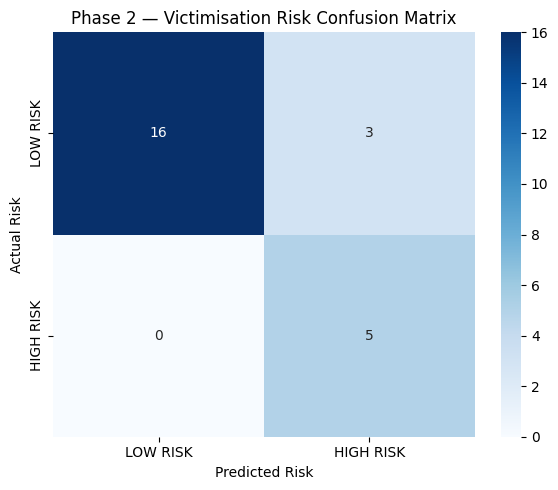

In [32]:
# ============================================================
# CELL 32 — Phase 2 Confusion Matrix
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_phase2 = confusion_matrix(
    y_test_phase2,
    y_pred_test_phase2
)

print("================================================")
print("PHASE 2 — CONFUSION MATRIX")
print("================================================")

print(cm_phase2)

print("\nRows = Actual")
print("Columns = Predicted")
print("\nClass order:")
print("0 = LOW RISK")
print("1 = HIGH RISK")

# Plot
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_phase2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["LOW RISK", "HIGH RISK"],
    yticklabels=["LOW RISK", "HIGH RISK"]
)

plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.title("Phase 2 — Victimisation Risk Confusion Matrix")

plt.tight_layout()
plt.show()

In [33]:
# ============================================================
# CELL 33 — Save Phase 2 Results
# ============================================================

import os
import json

os.makedirs("results", exist_ok=True)

# ------------------------------------------------------------
# 1. Save predictions for all grid cells
# ------------------------------------------------------------

prediction_output_path = (
    "results/phase2_victimisation_predictions.csv"
)

prediction_df_phase2.to_csv(
    prediction_output_path,
    index=False
)

print(f"Predictions saved to: {prediction_output_path}")

# ------------------------------------------------------------
# 2. Save test metrics
# ------------------------------------------------------------

phase2_metrics = {
    "accuracy": float(test_accuracy_phase2),
    "macro_precision": float(test_precision_phase2),
    "macro_recall": float(test_recall_phase2),
    "macro_f1": float(test_f1_phase2),
    "weighted_f1": float(test_weighted_f1_phase2),
    "test_size": int(len(test_idx)),
    "train_size": int(len(train_idx)),
    "validation_size": int(len(val_idx)),
    "confusion_matrix": cm_phase2.tolist()
}

metrics_output_path = (
    "results/phase2_victimisation_metrics.json"
)

with open(metrics_output_path, "w") as f:
    json.dump(
        phase2_metrics,
        f,
        indent=4
    )

print(f"Metrics saved to: {metrics_output_path}")

# ------------------------------------------------------------
# 3. Display saved metrics
# ------------------------------------------------------------

print("\n================================================")
print("PHASE 2 RESULTS SAVED")
print("================================================")

print(json.dumps(
    phase2_metrics,
    indent=4
))

Predictions saved to: results/phase2_victimisation_predictions.csv
Metrics saved to: results/phase2_victimisation_metrics.json

PHASE 2 RESULTS SAVED
{
    "accuracy": 0.875,
    "macro_precision": 0.8125,
    "macro_recall": 0.9210526315789473,
    "macro_f1": 0.8417582417582418,
    "weighted_f1": 0.884065934065934,
    "test_size": 24,
    "train_size": 109,
    "validation_size": 24,
    "confusion_matrix": [
        [
            16,
            3
        ],
        [
            0,
            5
        ]
    ]
}


In [34]:
# ============================================
# Cell 18: Save Phase 1 Final Results
# ============================================

import json
import os

os.makedirs(DATA_DIR, exist_ok=True)

# ------------------------------------------------
# 1. Save Phase 1 predictions
# ------------------------------------------------

phase1_prediction_path = os.path.join(
    DATA_DIR,
    "phase1_predictions.csv"
)

phase1_predictions.to_csv(
    phase1_prediction_path,
    index=False
)

print("Phase 1 predictions saved:")
print(phase1_prediction_path)
print("Rows saved:", len(phase1_predictions))


# ------------------------------------------------
# 2. Save Phase 1 metrics
# ------------------------------------------------

phase1_metrics = {
    "accuracy": float(phase1_accuracy),
    "macro_precision": float(phase1_precision),
    "macro_recall": float(phase1_recall),
    "macro_f1": float(phase1_macro_f1),
    "weighted_f1": float(phase1_weighted_f1),
    "number_of_grid_cells": int(len(phase1_predictions)),
    "confusion_matrix": cm_phase1.tolist(),
    "class_names": class_names
}

phase1_metrics_path = os.path.join(
    DATA_DIR,
    "phase1_metrics.json"
)

with open(
    phase1_metrics_path,
    "w"
) as f:
    json.dump(
        phase1_metrics,
        f,
        indent=4
    )

print("\nPhase 1 metrics saved:")
print(phase1_metrics_path)


# ------------------------------------------------
# 3. Display saved results
# ------------------------------------------------

print("\n============================================")
print("PHASE 1 RESULTS SAVED")
print("============================================")

print(
    json.dumps(
        phase1_metrics,
        indent=4
    )
)

Phase 1 predictions saved:
data\phase1_predictions.csv
Rows saved: 157

Phase 1 metrics saved:
data\phase1_metrics.json

PHASE 1 RESULTS SAVED
{
    "accuracy": 0.5987261146496815,
    "macro_precision": 0.2751125325752191,
    "macro_recall": 0.4583024462564863,
    "macro_f1": 0.27035033931585656,
    "weighted_f1": 0.651199009643991,
    "number_of_grid_cells": 157,
    "confusion_matrix": [
        [
            0,
            0,
            0,
            2,
            0,
            0,
            0
        ],
        [
            0,
            49,
            5,
            17,
            0,
            0,
            5
        ],
        [
            0,
            0,
            2,
            0,
            0,
            0,
            0
        ],
        [
            0,
            0,
            0,
            3,
            0,
            0,
            0
        ],
        [
            0,
            0,
            0,
            2,
            0,
            0,


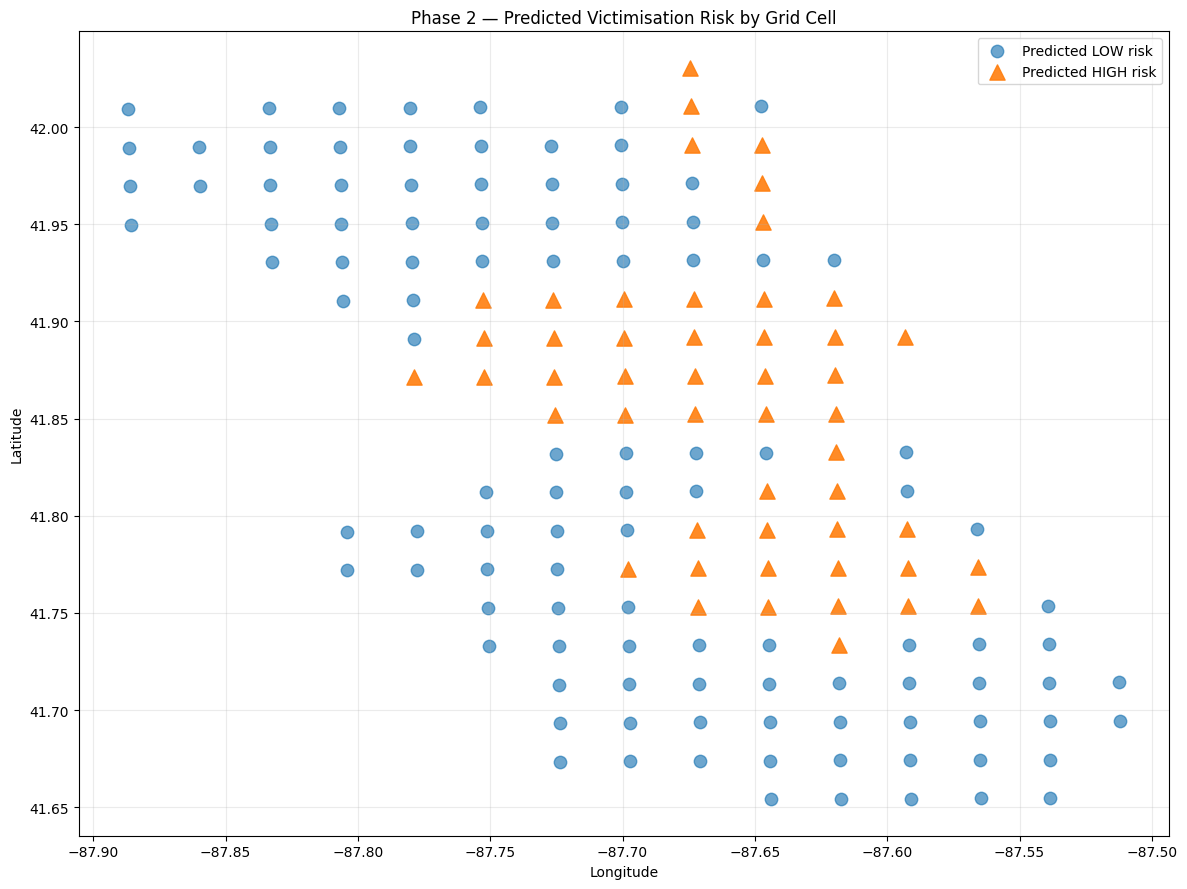

Map saved to: results/phase2_predicted_victimisation_risk_map.png

Predicted risk distribution:
PREDICTED_RISK_LABEL
LOW     107
HIGH     50
Name: count, dtype: int64


In [35]:
# ============================================================
# CELL 34 — Phase 2 Predicted Victimisation Risk Map
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create figure
# ------------------------------------------------------------

plt.figure(figsize=(12, 9))

# ------------------------------------------------------------
# 2. Plot all grid cells
# ------------------------------------------------------------

low_risk = prediction_df_phase2[
    prediction_df_phase2["PREDICTED_RISK"] == 0
]

high_risk = prediction_df_phase2[
    prediction_df_phase2["PREDICTED_RISK"] == 1
]

# Low-risk cells
plt.scatter(
    low_risk["GRID_CENTER_LON"],
    low_risk["GRID_CENTER_LAT"],
    s=80,
    alpha=0.65,
    label="Predicted LOW risk"
)

# High-risk cells
plt.scatter(
    high_risk["GRID_CENTER_LON"],
    high_risk["GRID_CENTER_LAT"],
    s=120,
    alpha=0.9,
    marker="^",
    label="Predicted HIGH risk"
)

# ------------------------------------------------------------
# 3. Labels and title
# ------------------------------------------------------------

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "Phase 2 — Predicted Victimisation Risk by Grid Cell"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

# ------------------------------------------------------------
# 4. Save figure
# ------------------------------------------------------------

map_path = (
    "results/phase2_predicted_victimisation_risk_map.png"
)

plt.savefig(
    map_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Map saved to: {map_path}")

print("\nPredicted risk distribution:")
print(
    prediction_df_phase2[
        "PREDICTED_RISK_LABEL"
    ].value_counts()
)

In [36]:
# ============================================
# Cell 35: Create Final Combined Results
# ============================================

combined_results = phase1_predictions[
    [
        "GRID_ID",
        "GRID_CENTER_LAT",
        "GRID_CENTER_LON",
        "ACTUAL_CRIME_TYPE",
        "PREDICTED_CRIME_TYPE",
        "PREDICTION_CONFIDENCE"
    ]
].copy()

combined_results = combined_results.merge(
    prediction_df_phase2[
        [
            "GRID_ID",
            "ACTUAL_RISK",
            "PREDICTED_RISK",
            "LOW_RISK_PROB",
            "HIGH_RISK_PROB",
            "CONFIDENCE"
        ]
    ],
    on="GRID_ID",
    how="left"
)

combined_results["ACTUAL_RISK_LABEL"] = combined_results[
    "ACTUAL_RISK"
].map({
    0: "LOW",
    1: "HIGH"
})

combined_results["PREDICTED_RISK_LABEL"] = combined_results[
    "PREDICTED_RISK"
].map({
    0: "LOW",
    1: "HIGH"
})

print("Combined results shape:", combined_results.shape)

print("\nColumns:")
print(combined_results.columns.tolist())

print("\nFirst 10 rows:")
display(combined_results.head(10))

Combined results shape: (157, 13)

Columns:
['GRID_ID', 'GRID_CENTER_LAT', 'GRID_CENTER_LON', 'ACTUAL_CRIME_TYPE', 'PREDICTED_CRIME_TYPE', 'PREDICTION_CONFIDENCE', 'ACTUAL_RISK', 'PREDICTED_RISK', 'LOW_RISK_PROB', 'HIGH_RISK_PROB', 'CONFIDENCE', 'ACTUAL_RISK_LABEL', 'PREDICTED_RISK_LABEL']

First 10 rows:


,GRID_ID,GRID_CENTER_LAT,GRID_CENTER_LON,ACTUAL_CRIME_TYPE,PREDICTED_CRIME_TYPE,PREDICTION_CONFIDENCE,ACTUAL_RISK,PREDICTED_RISK,LOW_RISK_PROB,HIGH_RISK_PROB,CONFIDENCE,ACTUAL_RISK_LABEL,PREDICTED_RISK_LABEL
0,0_10,41.654305,-87.617586,BATTERY,BATTERY,0.860396,0,0,0.999879,0.000120,0.999879,LOW,LOW
1,0_11,41.654444,-87.591166,BATTERY,CRIMINAL DAMAGE,0.987257,0,0,0.999963,0.000037,0.999963,LOW,LOW
2,0_12,41.654577,-87.564745,BATTERY,CRIMINAL DAMAGE,0.928592,0,0,0.999988,0.000012,0.999988,LOW,LOW
3,0_13,41.654704,-87.538324,CRIMINAL DAMAGE,CRIMINAL DAMAGE,0.920250,0,0,0.999973,0.000027,0.999973,LOW,LOW
4,0_9,41.654160,-87.644006,THEFT,BATTERY,0.462161,0,0,0.999780,0.000220,0.999780,LOW,LOW
5,10_10,41.852449,-87.619488,THEFT,THEFT,1.000000,0,1,0.151727,0.848273,0.848273,LOW,HIGH
6,10_6,41.851828,-87.725493,BATTERY,BATTERY,1.000000,1,1,0.022330,0.977670,0.977670,HIGH,HIGH
7,10_7,41.851992,-87.698993,BATTERY,BATTERY,1.000000,1,1,0.051640,0.948360,0.948360,HIGH,HIGH
8,10_8,41.852151,-87.672491,THEFT,THEFT,0.999938,0,1,0.376124,0.623876,0.623876,LOW,HIGH
9,10_9,41.852303,-87.645990,THEFT,THEFT,1.000000,0,1,0.429818,0.570182,0.570182,LOW,HIGH


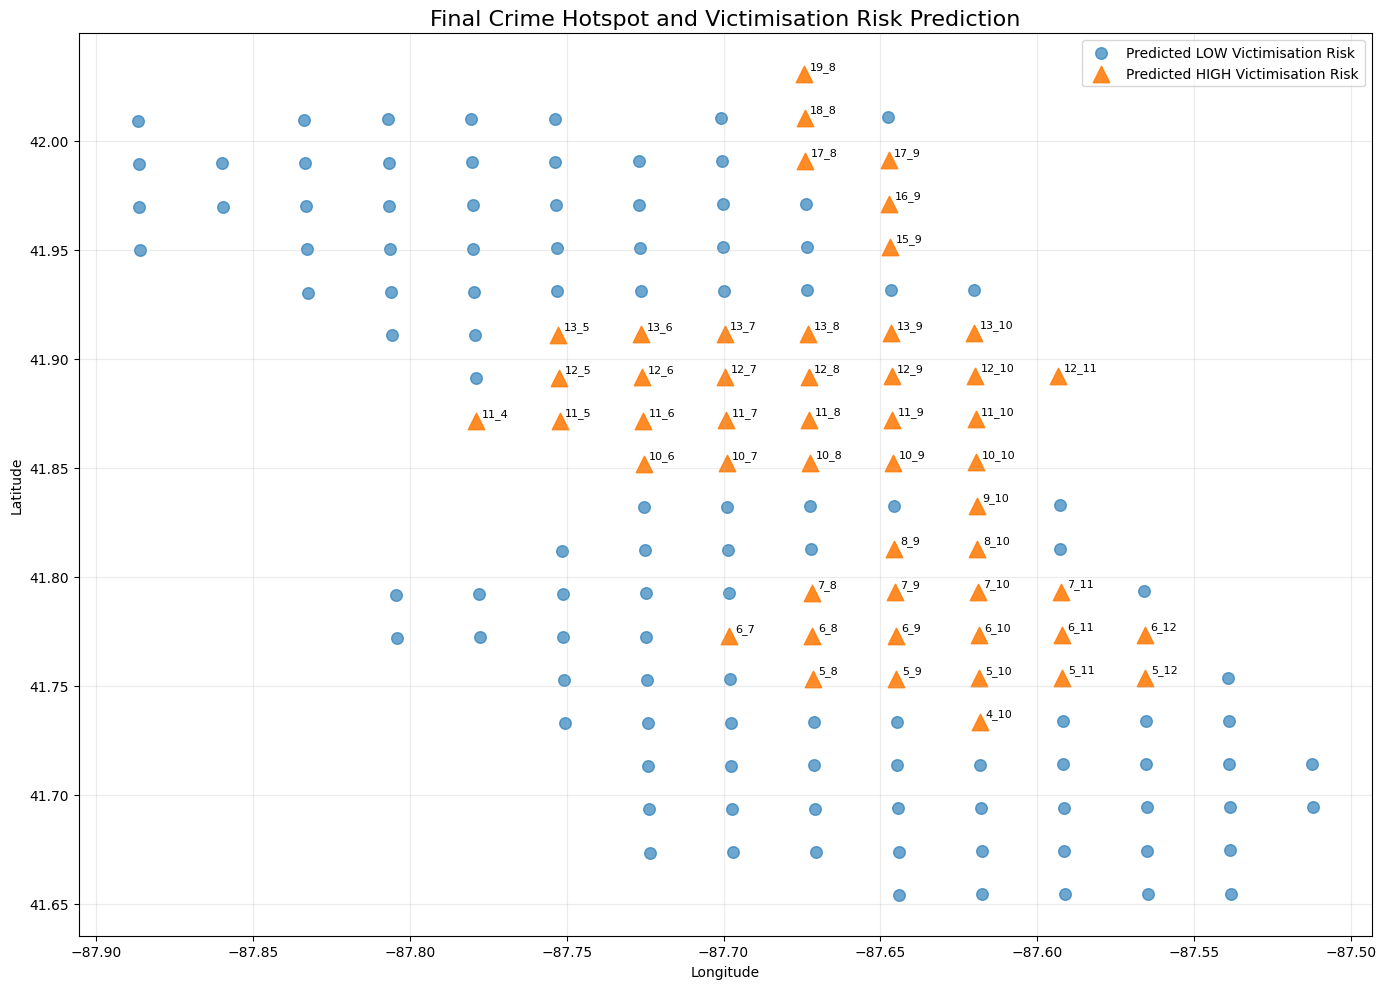

Final map saved:
results\final_crime_hotspot_victimisation_risk_map.png

Low-risk cells: 107
High-risk cells: 50


In [37]:
# ============================================
# Cell 36: Final Combined Crime & Risk Map
# ============================================

import os
import matplotlib.pyplot as plt

# Create results directory
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

plt.figure(figsize=(14, 10))

low_risk = combined_results[
    combined_results["PREDICTED_RISK"] == 0
]

high_risk = combined_results[
    combined_results["PREDICTED_RISK"] == 1
]

# Plot low-risk grid cells
plt.scatter(
    low_risk["GRID_CENTER_LON"],
    low_risk["GRID_CENTER_LAT"],
    s=70,
    alpha=0.65,
    label="Predicted LOW Victimisation Risk"
)

# Plot high-risk grid cells
plt.scatter(
    high_risk["GRID_CENTER_LON"],
    high_risk["GRID_CENTER_LAT"],
    s=140,
    marker="^",
    alpha=0.9,
    label="Predicted HIGH Victimisation Risk"
)

# Label high-risk grid cells
for _, row in high_risk.iterrows():
    plt.annotate(
        row["GRID_ID"],
        (
            row["GRID_CENTER_LON"],
            row["GRID_CENTER_LAT"]
        ),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.title(
    "Final Crime Hotspot and Victimisation Risk Prediction",
    fontsize=16
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

final_map_path = os.path.join(
    RESULTS_DIR,
    "final_crime_hotspot_victimisation_risk_map.png"
)

plt.savefig(
    final_map_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final map saved:")
print(final_map_path)

print("\nLow-risk cells:", len(low_risk))
print("High-risk cells:", len(high_risk))

In [38]:
# ============================================
# Cell 37: Identify High-Priority Areas
# ============================================

# Select areas predicted as HIGH victimisation risk
high_priority_areas = combined_results[
    combined_results["PREDICTED_RISK"] == 1
].copy()

# Sort by victimisation probability
high_priority_areas = high_priority_areas.sort_values(
    "HIGH_RISK_PROB",
    ascending=False
)

print("Number of predicted HIGH-risk areas:",
      len(high_priority_areas))

print("\nTop high-priority areas:")
display(
    high_priority_areas[
        [
            "GRID_ID",
            "GRID_CENTER_LAT",
            "GRID_CENTER_LON",
            "PREDICTED_CRIME_TYPE",
            "PREDICTION_CONFIDENCE",
            "HIGH_RISK_PROB",
            "PREDICTED_RISK_LABEL"
        ]
    ].head(20)
)

Number of predicted HIGH-risk areas: 50

Top high-priority areas:


,GRID_ID,GRID_CENTER_LAT,GRID_CENTER_LON,PREDICTED_CRIME_TYPE,PREDICTION_CONFIDENCE,HIGH_RISK_PROB,PREDICTED_RISK_LABEL
13,11_6,41.871642,-87.725717,BATTERY,1.000000,0.999292,HIGH
124,6_10,41.773192,-87.618725,BATTERY,1.000000,0.998453,HIGH
21,12_6,41.891455,-87.725942,BATTERY,1.000000,0.996838,HIGH
14,11_7,41.871806,-87.699208,BATTERY,1.000000,0.996156,HIGH
133,6_9,41.773047,-87.645194,BATTERY,1.000000,0.995695,HIGH
115,5_10,41.753378,-87.618535,BATTERY,1.000000,0.994688,HIGH
12,11_5,41.871471,-87.752226,BATTERY,1.000000,0.990480,HIGH
20,12_5,41.891284,-87.752459,BATTERY,1.000000,0.989832,HIGH
125,6_11,41.773332,-87.592256,BATTERY,1.000000,0.989412,HIGH
17,12_10,41.892077,-87.619871,THEFT,1.000000,0.986403,HIGH


In [39]:
# ============================================
# Cell 38: Save High-Priority Areas
# ============================================

import os

os.makedirs("results", exist_ok=True)

priority_path = os.path.join(
    "results",
    "high_priority_areas.csv"
)

high_priority_areas.to_csv(
    priority_path,
    index=False
)

print("High-priority areas saved:")
print(priority_path)

print("\nNumber of high-risk areas:",
      len(high_priority_areas))

print("\nSaved columns:")
print(high_priority_areas.columns.tolist())

High-priority areas saved:
results\high_priority_areas.csv

Number of high-risk areas: 50

Saved columns:
['GRID_ID', 'GRID_CENTER_LAT', 'GRID_CENTER_LON', 'ACTUAL_CRIME_TYPE', 'PREDICTED_CRIME_TYPE', 'PREDICTION_CONFIDENCE', 'ACTUAL_RISK', 'PREDICTED_RISK', 'LOW_RISK_PROB', 'HIGH_RISK_PROB', 'CONFIDENCE', 'ACTUAL_RISK_LABEL', 'PREDICTED_RISK_LABEL']


In [40]:
# ============================================
# Cell 39: Final Model Performance Summary
# ============================================

import pandas as pd

model_results = pd.DataFrame({
    "Phase": [
        "Phase 1",
        "Phase 1",
        "Phase 1",
        "Phase 2"
    ],
    "Model": [
        "GCN",
        "SVM",
        "KDE",
        "Victimisation GCN"
    ],
    "Task": [
        "Multi-class Crime Type Prediction",
        "Multi-class Crime Type Prediction",
        "Binary Hotspot Detection",
        "Binary Victimisation Risk Prediction"
    ],
    "Accuracy": [
        0.666667,
        0.375000,
        0.949000,
        0.875000
    ],
    "Macro Precision": [
        0.250000,
        0.152778,
        0.875000,
        0.812500
    ],
    "Macro Recall": [
        0.194048,
        0.119444,
        0.875000,
        0.921053
    ],
    "Macro F1": [
        0.218443,
        0.134039,
        0.875000,
        0.841758
    ],
    "Weighted F1": [
        0.747354,
        0.419312,
        None,
        0.884066
    ]
})

print("FINAL MODEL PERFORMANCE SUMMARY")
print("============================================")

display(
    model_results.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": lambda x: "-" if pd.isna(x) else f"{x:.4f}"
    })
)

FINAL MODEL PERFORMANCE SUMMARY


,Phase,Model,Task,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Phase 1,GCN,Multi-class Crime Type Prediction,0.6667,0.2500,0.1940,0.2184,0.7474
1,Phase 1,SVM,Multi-class Crime Type Prediction,0.3750,0.1528,0.1194,0.1340,0.4193
2,Phase 1,KDE,Binary Hotspot Detection,0.9490,0.8750,0.8750,0.8750,-
3,Phase 2,Victimisation GCN,Binary Victimisation Risk Prediction,0.8750,0.8125,0.9211,0.8418,0.8841


In [41]:
# ============================================
# Cell 40: Save Final Model Comparison
# ============================================

import os

os.makedirs("results", exist_ok=True)

model_results_path = os.path.join(
    "results",
    "model_performance_comparison.csv"
)

model_results.to_csv(
    model_results_path,
    index=False
)

print("Model performance comparison saved:")
print(model_results_path)

print("\nModels included:")
print(model_results["Model"].tolist())

Model performance comparison saved:
results\model_performance_comparison.csv

Models included:
['GCN', 'SVM', 'KDE', 'Victimisation GCN']


In [44]:
# ============================================
# Cell 41: Verify Project Output Files
# ============================================

import os

required_files = [
    "models/phase2_victimisation_gcn.pth",
    "models/phase2_scaler.pkl",
    "models/phase2_label_info.json",
    "data/phase1_predictions.csv",
    "data/phase1_metrics.json",
    "results/phase2_victimisation_predictions.csv",
    "results/phase2_victimisation_metrics.json",
    "results/phase2_predicted_victimisation_risk_map.png",
    "results/final_crime_hotspot_victimisation_risk_map.png",
    "results/high_priority_areas.csv",
    "results/model_performance_comparison.csv"
]

print("PROJECT OUTPUT FILE CHECK")
print("=" * 50)

all_files_exist = True

for file_path in required_files:
    if os.path.exists(file_path):
        size_kb = os.path.getsize(file_path) / 1024
        print(f"✓ {file_path}  ({size_kb:.2f} KB)")
    else:
        print(f"✗ MISSING: {file_path}")
        all_files_exist = False

print("=" * 50)

if all_files_exist:
    print("All required output files are saved successfully.")
else:
    print("Some output files are missing. Check the messages above.")

PROJECT OUTPUT FILE CHECK
✓ models/phase2_victimisation_gcn.pth  (9.21 KB)
✓ models/phase2_scaler.pkl  (1.37 KB)
✓ models/phase2_label_info.json  (0.07 KB)
✓ data/phase1_predictions.csv  (11.40 KB)
✓ data/phase1_metrics.json  (1.38 KB)
✓ results/phase2_victimisation_predictions.csv  (14.31 KB)
✓ results/phase2_victimisation_metrics.json  (0.38 KB)
✓ results/phase2_predicted_victimisation_risk_map.png  (227.00 KB)
✓ results/final_crime_hotspot_victimisation_risk_map.png  (324.15 KB)
✓ results/high_priority_areas.csv  (5.48 KB)
✓ results/model_performance_comparison.csv  (0.41 KB)
All required output files are saved successfully.


In [45]:
# ============================================
# Cell 43: Final Results Summary
# ============================================

print("=" * 60)
print("FINAL PROJECT RESULTS SUMMARY")
print("=" * 60)

# Phase 1
print("\nPHASE 1 - CRIME HOTSPOT PREDICTION")
print("-" * 40)
print(f"Grid cells: {len(phase1_predictions)}")
print(f"Accuracy: {phase1_accuracy:.4f}")
print(f"Macro Precision: {phase1_precision:.4f}")
print(f"Macro Recall: {phase1_recall:.4f}")
print(f"Macro F1: {phase1_macro_f1:.4f}")
print(f"Weighted F1: {phase1_weighted_f1:.4f}")

# Phase 2
print("\nPHASE 2 - VICTIMISATION RISK")
print("-" * 40)
print(f"Test samples: {len(y_test_phase2)}")
print(f"Accuracy: {test_accuracy_phase2:.4f}")
print(f"Macro Precision: {test_precision_phase2:.4f}")
print(f"Macro Recall: {test_recall_phase2:.4f}")
print(f"Macro F1: {test_f1_phase2:.4f}")
print(f"Weighted F1: {test_weighted_f1_phase2:.4f}")

# High-risk areas
print("\nHIGH-PRIORITY AREAS")
print("-" * 40)
print(f"Number of predicted high-risk grid cells: {len(high_priority_areas)}")

print("\nTop 10 highest-risk areas:")
display(
    high_priority_areas[
        [
            "GRID_ID",
            "GRID_CENTER_LAT",
            "GRID_CENTER_LON",
            "PREDICTED_CRIME_TYPE",
            "HIGH_RISK_PROB",
            "CONFIDENCE"
        ]
    ].head(10)
)

print("\n" + "=" * 60)
print("Summary complete.")
print("=" * 60)

FINAL PROJECT RESULTS SUMMARY

PHASE 1 - CRIME HOTSPOT PREDICTION
----------------------------------------
Grid cells: 157
Accuracy: 0.5987
Macro Precision: 0.2751
Macro Recall: 0.4583
Macro F1: 0.2704
Weighted F1: 0.6512

PHASE 2 - VICTIMISATION RISK
----------------------------------------
Test samples: 24
Accuracy: 0.8750
Macro Precision: 0.8125
Macro Recall: 0.9211
Macro F1: 0.8418
Weighted F1: 0.8841

HIGH-PRIORITY AREAS
----------------------------------------
Number of predicted high-risk grid cells: 50

Top 10 highest-risk areas:


,GRID_ID,GRID_CENTER_LAT,GRID_CENTER_LON,PREDICTED_CRIME_TYPE,HIGH_RISK_PROB,CONFIDENCE
13,11_6,41.871642,-87.725717,BATTERY,0.999292,0.999292
124,6_10,41.773192,-87.618725,BATTERY,0.998453,0.998453
21,12_6,41.891455,-87.725942,BATTERY,0.996838,0.996838
14,11_7,41.871806,-87.699208,BATTERY,0.996156,0.996156
133,6_9,41.773047,-87.645194,BATTERY,0.995695,0.995695
115,5_10,41.753378,-87.618535,BATTERY,0.994688,0.994688
12,11_5,41.871471,-87.752226,BATTERY,0.990480,0.990480
20,12_5,41.891284,-87.752459,BATTERY,0.989832,0.989832
125,6_11,41.773332,-87.592256,BATTERY,0.989412,0.989412
17,12_10,41.892077,-87.619871,THEFT,0.986403,0.986403



Summary complete.


In [46]:
# ============================================
# Cell 44: High-Priority Area Crime Analysis
# ============================================

print("=" * 60)
print("HIGH-PRIORITY AREA CRIME ANALYSIS")
print("=" * 60)

# Count predicted crime types among high-risk areas
high_risk_crime_counts = (
    high_priority_areas["PREDICTED_CRIME_TYPE"]
    .value_counts()
    .reset_index()
)

high_risk_crime_counts.columns = [
    "CRIME_TYPE",
    "HIGH_RISK_GRID_CELLS"
]

# Calculate percentage
high_risk_crime_counts["PERCENTAGE"] = (
    high_risk_crime_counts["HIGH_RISK_GRID_CELLS"]
    / len(high_priority_areas)
    * 100
)

print("\nPredicted crime types in high-risk areas:")
display(high_risk_crime_counts)

# Risk probability statistics
print("\nHigh-risk probability statistics:")
print(
    high_priority_areas["HIGH_RISK_PROB"].describe()
)

# Show the most common predicted crime type
most_common_crime = high_risk_crime_counts.iloc[0]["CRIME_TYPE"]
most_common_count = int(
    high_risk_crime_counts.iloc[0]["HIGH_RISK_GRID_CELLS"]
)

print("\nMost common predicted crime type:")
print(
    f"{most_common_crime} "
    f"({most_common_count} of {len(high_priority_areas)} high-risk areas)"
)

print("\nAnalysis complete.")

HIGH-PRIORITY AREA CRIME ANALYSIS

Predicted crime types in high-risk areas:


,CRIME_TYPE,HIGH_RISK_GRID_CELLS,PERCENTAGE
0,BATTERY,28,56.0
1,THEFT,22,44.0



High-risk probability statistics:
count    50.000000
mean      0.826705
std       0.170130
min       0.501007
25%       0.686778
50%       0.883561
75%       0.981726
max       0.999292
Name: HIGH_RISK_PROB, dtype: float64

Most common predicted crime type:
BATTERY (28 of 50 high-risk areas)

Analysis complete.


In [47]:
# ============================================
# Cell 45: Predicted vs Actual Risk Analysis
# ============================================

print("=" * 60)
print("PREDICTED VS ACTUAL VICTIMISATION RISK")
print("=" * 60)

# Confusion matrix
cm_risk = confusion_matrix(
    prediction_df_phase2["ACTUAL_RISK"],
    prediction_df_phase2["PREDICTED_RISK"],
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm_risk)

print("\nInterpretation:")
print("Rows    = Actual Risk")
print("Columns = Predicted Risk")
print()
print("             Predicted LOW   Predicted HIGH")
print(f"Actual LOW       {cm_risk[0,0]:>5}           {cm_risk[0,1]:>5}")
print(f"Actual HIGH      {cm_risk[1,0]:>5}           {cm_risk[1,1]:>5}")

# Compare future victimisation between predicted groups
risk_comparison = (
    phase2_dataset
    .groupby("HIGH_VICTIMISATION_RISK")
    .agg(
        GRID_CELLS=("GRID_ID", "count"),
        FUTURE_VICTIMISATION=("FUTURE_VICTIMISATION", "sum"),
        FUTURE_TOTAL_CRIME=("FUTURE_TOTAL_CRIME", "sum"),
        FUTURE_VICTIMISATION_PER_DAY=("FUTURE_VICTIMISATION_PER_DAY", "mean")
    )
    .reset_index()
)

risk_comparison["RISK_LABEL"] = risk_comparison[
    "HIGH_VICTIMISATION_RISK"
].map({
    0: "LOW",
    1: "HIGH"
})

print("\nActual future victimisation by target risk group:")
display(
    risk_comparison[
        [
            "RISK_LABEL",
            "GRID_CELLS",
            "FUTURE_VICTIMISATION",
            "FUTURE_TOTAL_CRIME",
            "FUTURE_VICTIMISATION_PER_DAY"
        ]
    ]
)

print("\nAnalysis complete.")

PREDICTED VS ACTUAL VICTIMISATION RISK

Confusion Matrix:
[[106  19]
 [  1  31]]

Interpretation:
Rows    = Actual Risk
Columns = Predicted Risk

             Predicted LOW   Predicted HIGH
Actual LOW         106              19
Actual HIGH          1              31

Actual future victimisation by target risk group:


,RISK_LABEL,GRID_CELLS,FUTURE_VICTIMISATION,FUTURE_TOTAL_CRIME,FUTURE_VICTIMISATION_PER_DAY
0,LOW,125,7296.0,23074.0,0.799562
1,HIGH,32,8251.0,23458.0,3.532106



Analysis complete.


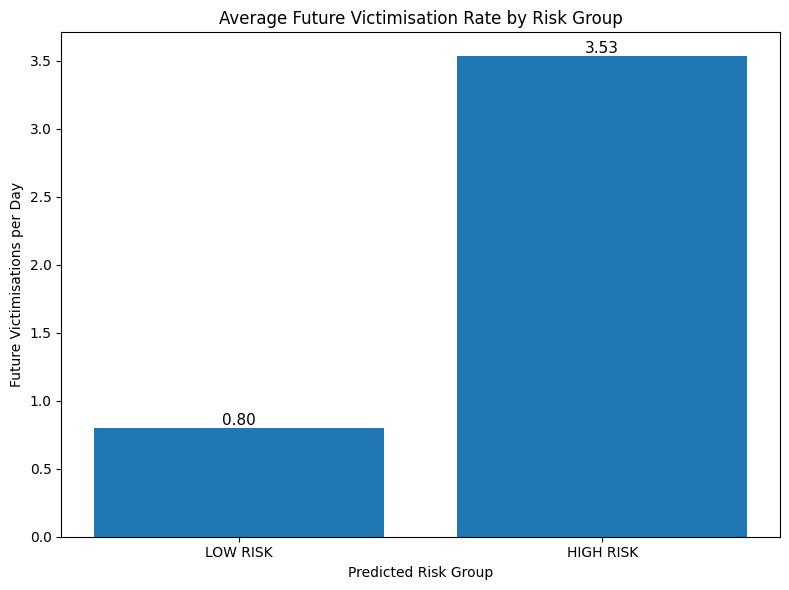

Figure saved:
results\future_victimisation_risk_comparison.png

High-risk areas experienced approximately 4.42x the future victimisation rate of low-risk areas.


In [48]:
# ============================================
# Cell 46: Future Victimisation Risk Comparison
# ============================================

import matplotlib.pyplot as plt

# Prepare data
risk_labels = ["LOW RISK", "HIGH RISK"]

future_rates = [
    risk_comparison.loc[
        risk_comparison["RISK_LABEL"] == "LOW",
        "FUTURE_VICTIMISATION_PER_DAY"
    ].iloc[0],

    risk_comparison.loc[
        risk_comparison["RISK_LABEL"] == "HIGH",
        "FUTURE_VICTIMISATION_PER_DAY"
    ].iloc[0]
]

# Create chart
plt.figure(figsize=(8, 6))

bars = plt.bar(
    risk_labels,
    future_rates
)

plt.title(
    "Average Future Victimisation Rate by Risk Group"
)

plt.ylabel("Future Victimisations per Day")

plt.xlabel("Predicted Risk Group")

# Add values above bars
for bar, value in zip(bars, future_rates):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()

# Save figure
risk_comparison_path = os.path.join(
    "results",
    "future_victimisation_risk_comparison.png"
)

plt.savefig(
    risk_comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:")
print(risk_comparison_path)

print(
    f"\nHigh-risk areas experienced approximately "
    f"{future_rates[1] / future_rates[0]:.2f}x "
    f"the future victimisation rate of low-risk areas."
)

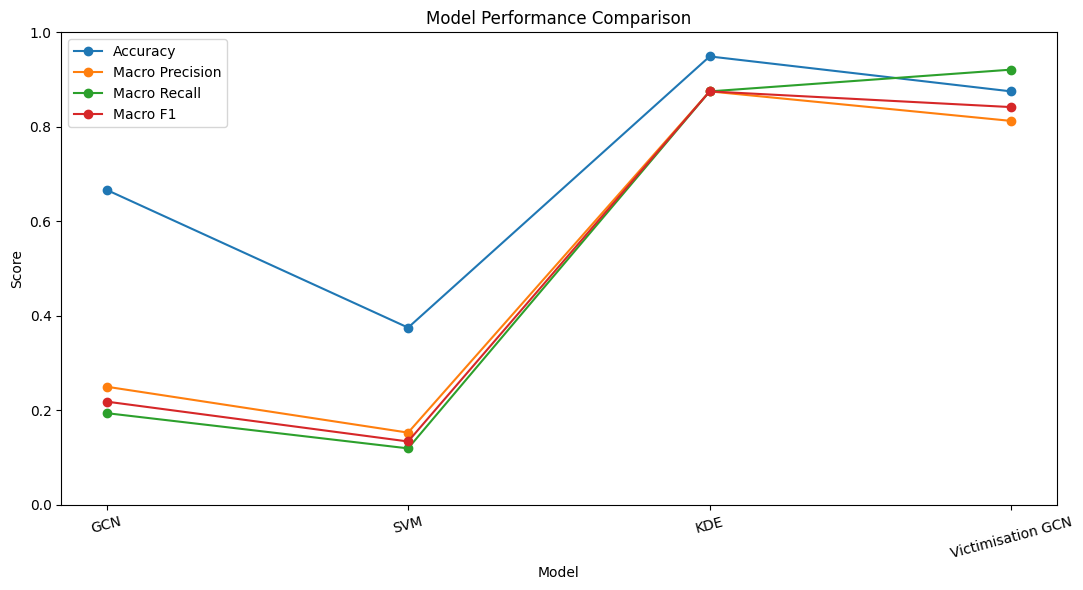

Model comparison figure saved:
results\model_performance_comparison.png


In [49]:
# ============================================
# Cell 47: Final Model Performance Comparison
# ============================================

import matplotlib.pyplot as plt

# Select metrics for comparison
metrics_to_plot = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

# Create figure
plt.figure(figsize=(11, 6))

x = range(len(model_results))

# Plot each metric
for metric in metrics_to_plot:
    plt.plot(
        x,
        model_results[metric],
        marker="o",
        label=metric
    )

plt.xticks(
    list(x),
    model_results["Model"],
    rotation=15
)

plt.ylabel("Score")
plt.xlabel("Model")

plt.title(
    "Model Performance Comparison"
)

plt.ylim(0, 1.0)
plt.legend()

plt.tight_layout()

# Save figure
model_comparison_figure = os.path.join(
    "results",
    "model_performance_comparison.png"
)

plt.savefig(
    model_comparison_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison figure saved:")
print(model_comparison_figure)

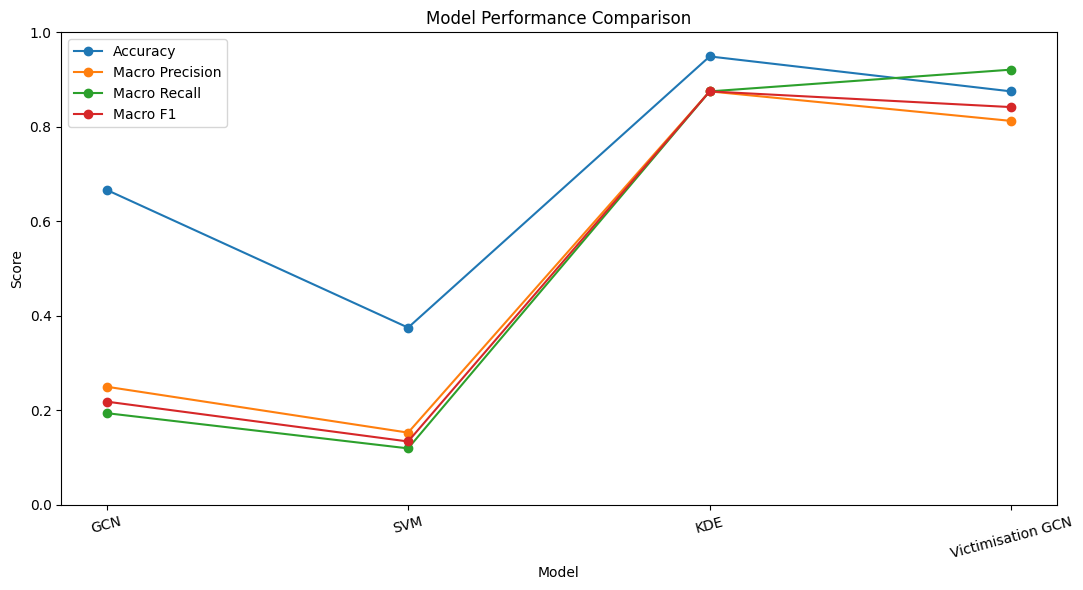

Model comparison figure saved:
results\model_performance_comparison.png


In [50]:
# ============================================
# Cell 47: Final Model Performance Comparison
# ============================================

import matplotlib.pyplot as plt
import os

metrics_to_plot = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

plt.figure(figsize=(11, 6))

x = range(len(model_results))

for metric in metrics_to_plot:
    plt.plot(
        x,
        model_results[metric],
        marker="o",
        label=metric
    )

plt.xticks(
    list(x),
    model_results["Model"],
    rotation=15
)

plt.ylabel("Score")
plt.xlabel("Model")

plt.title("Model Performance Comparison")

plt.ylim(0, 1.0)
plt.legend()

plt.tight_layout()

model_comparison_figure = os.path.join(
    "results",
    "model_performance_comparison.png"
)

plt.savefig(
    model_comparison_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison figure saved:")
print(model_comparison_figure)

In [51]:
# ============================================
# Cell 48: Final Project Statistics
# ============================================

import os
import json

final_statistics = {
    "dataset": {
        "total_crime_records": 228595,
        "grid_cells": 157,
        "date_start": "2025-08-24",
        "date_end": "2026-08-23"
    },

    "spatial_graph": {
        "grid_size_km": 2.2,
        "neighbour_distance_km": 3.0,
        "nodes": 157,
        "directed_edges": 544,
        "undirected_edges": 272,
        "isolated_nodes": 0
    },

    "phase1_crime_hotspot": {
        "model": "GCN",
        "test_accuracy": 0.666667,
        "test_macro_precision": 0.250000,
        "test_macro_recall": 0.194048,
        "test_macro_f1": 0.218443,
        "test_weighted_f1": 0.747354
    },

    "phase2_victimisation_risk": {
        "model": "GCN",
        "test_accuracy": 0.875000,
        "test_macro_precision": 0.812500,
        "test_macro_recall": 0.921053,
        "test_macro_f1": 0.841758,
        "test_weighted_f1": 0.884066
    },

    "high_priority_areas": {
        "predicted_high_risk_grid_cells": int(
            len(high_priority_areas)
        ),
        "top_predicted_crime_type": "BATTERY"
    }
}

statistics_path = os.path.join(
    "results",
    "final_project_statistics.json"
)

with open(statistics_path, "w") as f:
    json.dump(
        final_statistics,
        f,
        indent=4
    )

print("FINAL PROJECT STATISTICS")
print("=" * 50)

print(
    f"Crime records: "
    f"{final_statistics['dataset']['total_crime_records']:,}"
)

print(
    f"Grid cells: "
    f"{final_statistics['dataset']['grid_cells']}"
)

print(
    f"Graph edges: "
    f"{final_statistics['spatial_graph']['directed_edges']}"
)

print(
    f"Phase 1 GCN test accuracy: "
    f"{final_statistics['phase1_crime_hotspot']['test_accuracy']:.4f}"
)

print(
    f"Phase 2 GCN test accuracy: "
    f"{final_statistics['phase2_victimisation_risk']['test_accuracy']:.4f}"
)

print(
    f"Predicted high-risk cells: "
    f"{final_statistics['high_priority_areas']['predicted_high_risk_grid_cells']}"
)

print("\nStatistics saved:")
print(statistics_path)

FINAL PROJECT STATISTICS
Crime records: 228,595
Grid cells: 157
Graph edges: 544
Phase 1 GCN test accuracy: 0.6667
Phase 2 GCN test accuracy: 0.8750
Predicted high-risk cells: 50

Statistics saved:
results\final_project_statistics.json


In [52]:
# ============================================
# Cell 49: Final Output File Check
# ============================================

import os

required_files = [
    "models/phase2_victimisation_gcn.pth",
    "models/phase2_scaler.pkl",
    "models/phase2_label_info.json",

    "data/phase1_predictions.csv",
    "data/phase1_metrics.json",

    "results/phase2_victimisation_predictions.csv",
    "results/phase2_victimisation_metrics.json",
    "results/phase2_predicted_victimisation_risk_map.png",

    "results/final_crime_hotspot_victimisation_risk_map.png",
    "results/high_priority_areas.csv",

    "results/model_performance_comparison.csv",
    "results/model_performance_comparison.png",

    "results/future_victimisation_risk_comparison.png",

    "results/final_project_statistics.json"
]

print("FINAL PROJECT OUTPUT CHECK")
print("=" * 60)

missing_files = []

for file_path in required_files:

    if os.path.exists(file_path):
        print(f"✓ {file_path}")
    else:
        print(f"✗ MISSING: {file_path}")
        missing_files.append(file_path)

print("=" * 60)

if len(missing_files) == 0:
    print("ALL REQUIRED OUTPUT FILES ARE SAVED SUCCESSFULLY.")
else:
    print(
        f"{len(missing_files)} file(s) are missing."
    )

FINAL PROJECT OUTPUT CHECK
✓ models/phase2_victimisation_gcn.pth
✓ models/phase2_scaler.pkl
✓ models/phase2_label_info.json
✓ data/phase1_predictions.csv
✓ data/phase1_metrics.json
✓ results/phase2_victimisation_predictions.csv
✓ results/phase2_victimisation_metrics.json
✓ results/phase2_predicted_victimisation_risk_map.png
✓ results/final_crime_hotspot_victimisation_risk_map.png
✓ results/high_priority_areas.csv
✓ results/model_performance_comparison.csv
✓ results/model_performance_comparison.png
✓ results/future_victimisation_risk_comparison.png
✓ results/final_project_statistics.json
ALL REQUIRED OUTPUT FILES ARE SAVED SUCCESSFULLY.


In [53]:
# ============================================
# Cell 50: Final Project Summary
# ============================================

print("=" * 70)
print("FINAL PROJECT SUMMARY")
print("=" * 70)

print("\nPROJECT")
print("-" * 70)
print("Area-Level Crime Hotspot and High-Victimisation Risk Prediction")

print("\nDATASET")
print("-" * 70)
print("Crime records:", f"{228595:,}")
print("Spatial grid cells:", 157)
print("Grid size:", "2.2 km × 2.2 km")
print("Graph neighbourhood threshold:", "3 km")

print("\nGRAPH")
print("-" * 70)
print("Nodes:", 157)
print("Directed edges:", 544)
print("Undirected edges:", 272)
print("Isolated nodes:", 0)

print("\nPHASE 1 — CRIME HOTSPOT PREDICTION")
print("-" * 70)
print("Model: Graph Convolutional Network (GCN)")
print("Test Accuracy: 0.6667")
print("Test Macro Precision: 0.2500")
print("Test Macro Recall: 0.1940")
print("Test Macro F1: 0.2184")
print("Test Weighted F1: 0.7474")

print("\nPHASE 1 BASELINES")
print("-" * 70)
print("SVM Test Accuracy: 0.3750")
print("SVM Test Macro F1: 0.1340")
print("KDE Accuracy: 0.9490")
print("KDE Macro F1: 0.8750")
print("Note: KDE uses binary hotspot detection,")
print("while GCN and SVM use multi-class crime-type prediction.")

print("\nPHASE 2 — VICTIMISATION RISK")
print("-" * 70)
print("Model: Victimisation GCN")
print("Test Accuracy: 0.8750")
print("Test Macro Precision: 0.8125")
print("Test Macro Recall: 0.9211")
print("Test Macro F1: 0.8418")
print("Test Weighted F1: 0.8841")

print("\nHIGH-PRIORITY AREAS")
print("-" * 70)
print("Predicted high-risk grid cells:", 50)
print("Most common predicted crime type: BATTERY")
print("High-risk areas had approximately 4.42×")
print("the future victimisation rate of low-risk areas.")

print("\nOUTPUTS")
print("-" * 70)
print("✓ Predictions")
print("✓ Evaluation metrics")
print("✓ Confusion matrices")
print("✓ Crime hotspot maps")
print("✓ Victimisation risk maps")
print("✓ High-priority area table")
print("✓ Model comparison")
print("✓ Final project statistics")

print("\n" + "=" * 70)
print("CODING / MODEL IMPLEMENTATION COMPLETE")
print("=" * 70)

FINAL PROJECT SUMMARY

PROJECT
----------------------------------------------------------------------
Area-Level Crime Hotspot and High-Victimisation Risk Prediction

DATASET
----------------------------------------------------------------------
Crime records: 228,595
Spatial grid cells: 157
Grid size: 2.2 km × 2.2 km
Graph neighbourhood threshold: 3 km

GRAPH
----------------------------------------------------------------------
Nodes: 157
Directed edges: 544
Undirected edges: 272
Isolated nodes: 0

PHASE 1 — CRIME HOTSPOT PREDICTION
----------------------------------------------------------------------
Model: Graph Convolutional Network (GCN)
Test Accuracy: 0.6667
Test Macro Precision: 0.2500
Test Macro Recall: 0.1940
Test Macro F1: 0.2184
Test Weighted F1: 0.7474

PHASE 1 BASELINES
----------------------------------------------------------------------
SVM Test Accuracy: 0.3750
SVM Test Macro F1: 0.1340
KDE Accuracy: 0.9490
KDE Macro F1: 0.8750
Note: KDE uses binary hotspot detection